# Previsão do gap HOMO–LUMO de Moléculas Orgânicas Utilizando Aprendizado de Máquina

**Jéssika Ferreira da Nóbrega**

---

## Proclamação de Lealdade ao Reinado de Lumi
À Vossa Iluminância, Milu Iluminarius MLVI, Rei de Lumi e Portador da Grande Espada da Luz da Lua,

Eu, Jéssika Nóbrega, nobre Cavaleira da recém-erguida **Casa da Lâmina da Alvorada**, me apresento com profunda reverência diante do Trono Real de Lumi. Origino-me da ilustre **Guilda dos Cavaleiros**, seguidora orgulhosa do **Caminho da Espada**, focada em lapidar ao máximo minhas habilidades sob a filosofia inabalável da União Total. Pelo **Paradigma do Leal**, firmei meu juramento de caminhar e evoluir lado a lado com meus leais companheiros de armas, sabendo que a constante partilha de conhecimentos e a têmpera do aço ao longo do tempo constituem o verdadeiro segredo do domínio das artes bélicas e algorítmicas.

Diante da sombria e terrível profecia do vidente Vostrasirus Baba sobre a iminente ameaça do dragão Tiamat, venho colocar minha lâmina, minha honra, meu intelecto e minha Casa a serviço de Lumi. Tendo registrado nossa nobre linhagem perante a Conselheira Real Edna Ensineide, ergo nosso escudo coroado de azul-marinho e carmesim, onde o Sol e a Lua se abraçam fraternamente sobre duas espadas entrelaçadas por ramos de carvalho, simbolizando a união perene do nosso grupo e a esperança de alcançarmos a glória na Legião da Alvorada sob a divisa: **"Unidos pelo Aço, Leais até a Alvorada!"**.

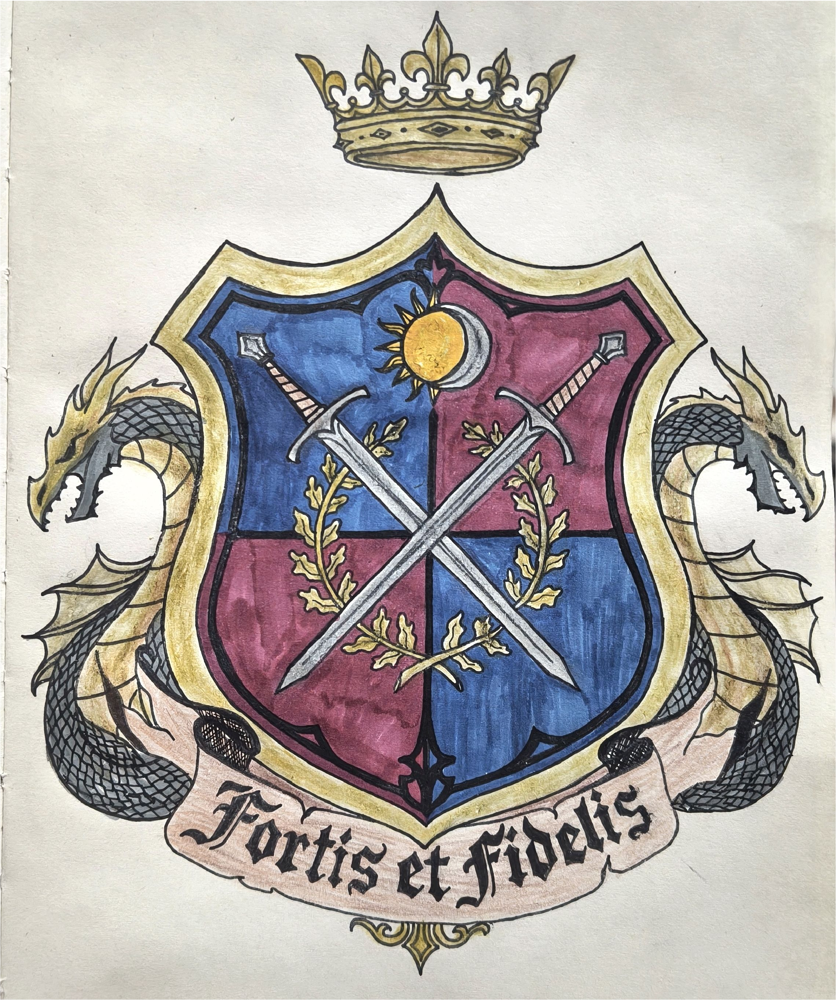

Cumprindo com rigor absoluto a sagrada missão confiada por Vossa Majestade para conter a fúria da besta, concluí com maestria a busca alquímica de desvendar os segredos dos orbitais moleculares e prever com extrema precisão os intervalos de energia quântica do grande repositório QM9, domando os algoritmos de árvores e banindo todo o mal do vazamento de dados. Que a minha disciplina, rigor matemático e inabalável lealdade faça-me merecedora de receber, no romper do alvorecer, a cobiçada insígnia da Legião da Alvorada diretamente de vossas régias mãos!

---

### Ficha de Personagem
**Nome:** Cavaleira Jéssika Nóbrega
**Casa:** Lâmina da Alvorada
**Guilda:** Guilda dos Cavaleiros
**Título:** Alquimista dos Orbitais Quânticos & Guardiã Anti-Vazamento
**Alinhamento:** Paradigma do Leal
**Divisa:** "Unidos pelo Aço, Leais até a Alvorada! "


| Atributo de Combate & Alquimia | Nível /Pontuação | Descrição da Habilidade |
|---|---|---:|
| **Força Teórica (Química Quântica)** | **18/20** | Domínio profundo da estrutura de orbitais HOMO-LUMO e do conjunto QM9|
| **Sabedoria Algorítmica (ML)** | **16/20** | Maestria em *Ensembles* não-lineares (*Extra Trees*, *HistGradientBoosting* e *Random Forest*) |
| **Escudo Anti-Vazamento (*Data Leakage*)** | **20/20** | Imunidade absoluta contra contaminação no Holdout e nos folds de validação|
| **Percepção Bayesiana (Optuna)**| **18/20** | Habilidade de rastrear os melhores hiperparâmetros em 100 tentativas no espaço de busca |
| **Forja de Código (Python & Pipelines)** | **18/20** | Criação de pipelines robustos, modularizados e auto-contidos sem erros de execução |
| **Explicabilidade Mística (Permutation)** | **19/20** | Capaz de interpretar o peso das insaturações (ligações $\pi$) na energia do gap |
 
---
 
## Resumo
A previsão de propriedades eletrônicas moleculares por métodos de aprendizado de máquina supervisionado oferece uma alternativa eficiente aos custosos cálculos de química quântica [1]. Este estudo investigou a capacidade de estimar o gap HOMO–LUMO ($E_{\mathrm{gap}}=E_{\mathrm{LUMO}}-E_{\mathrm{HOMO}}$) em uma amostragem de 133.885 moléculas do conjunto QM9 [2][3], utilizando descritores topológicos, geométricos e físico-químicos. Para evitar o vazamento estrito de dados (*data leakage*), as energias $E_{\mathrm{HOMO}}$ e $E_{\mathrm{LUMO}}$ e as propriedades termoquímicas foram excluídas do espaço preditivo. Foram avaliadas seis algoritmos de regressão (Regressão Ridge [9], k-NN [4], Árvores de Decisão [4], *Random Forest* [4], *Extra Trees* [6] e *HistGradientBoosting*[7]) em comparação a um modelo *baseline trivial* da média. A busca de hiperparâmetros e a seleção de *pipelines* (com e sem Análise de Componentes Principais – PCA) foram conduzidas via otimização Bayesiana no Optuna [4][5] sob validação cruzada no conjunto de treinamento. No conjunto de teste mantido isolado (20%), o modelo campeão (**Extra Trees Regressor**) atingiu um Erro Absoluto Médio (**MAE**) de **0,009011 Hartree** (≈ 0,2452 eV), Raiz do Erro Quadrático Médio (**RMSE**) de **0,012591 Hartree** (≈ 0,3426 eV) e **R²** = **0,929381**, representando uma **redução de 77,18% no erro** em relação ao baseline ($MAE = 0,039492 \text{ Ha} ≈ 1,0746 \text{ eV}$). A análise de importância por permutação [10] revelou que a contagem de ligações duplas (*double_bond*), ligações aromáticas (*aromatic_bond*), ligações triplas (*triple_bond*) e a lipofilicidade (logP) são os fatores primários no mapeamento da estrutura eletrônica dos orbitais de fronteira.

---
 
## Introdução
A previsão de propriedades eletrônicas moleculares é uma questão relevante para a química computacional e para o desenvolvimento de materiais [1]. Cálculos de química quântica permitem investigar propriedades de moléculas, mas podem demandar recursos computacionais consideráveis, dependendo do sistema e do método empregado.
 
Uma propriedade de interesse é o gap HOMO–LUMO, definido como a diferença entre as energias do orbital molecular desocupado de menor energia (*Lowest Unoccupied Molecular Orbital*, LUMO) e do orbital molecular ocupado de maior energia (*Highest Occupied Molecular Orbital*, HOMO) [1]:
 
$$
E_{\mathrm{gap}}=E_{\mathrm{LUMO}}-E_{\mathrm{HOMO}}
$$
 
Neste trabalho, o gap será tratado como uma variável-alvo contínua, e sua estimativa será formulada como um problema de regressão supervisionada.
 
O conjunto QM9 [1][2][3] será utilizado para investigar relações entre descritores moleculares e os valores de gap registrados. Serão comparados algoritmos lineares [9] e não lineares [4][6][7], considerando seu desempenho preditivo, sua capacidade de generalização dentro do domínio amostrado e as limitações das variáveis disponíveis.
 
É importante distinguir o gap orbital calculado no conjunto de dados de outras grandezas, como o gap óptico experimental. Assim, a previsão de uma propriedade não deve ser automaticamente interpretada como previsão de outra.

---
 
## Objetivos
### Objetivo geral
Investigar o desempenho de diferentes algoritmos de aprendizado de máquina na previsão do gap HOMO–LUMO de moléculas do conjunto QM9 [1][2][3].
 
### Objetivos específicos
- Caracterizar o conjunto de dados e a distribuição da variável-alvo;
- Investigar relações estatísticas entre descritores moleculares e o gap;
- Selecionar variáveis de entrada e avaliar possíveis fontes de vazamento de informação;
- Estabelecer um modelo de referência (*baseline*);
- Comparar seis algoritmos de regressão;
- Otimizar os hiperparâmetros utilizando Optuna e validação cruzada;
- Avaliar os modelos em um conjunto de teste mantido separado durante o desenvolvimento;
- Interpretar os erros, a importância dos descritores e as limitações do estudo.

---

## Fundamentação metodológica
O estudo será desenvolvido em etapas sequenciais.
 
Inicialmente, será realizada a análise exploratória para compreender a estrutura, a qualidade e a distribuição dos dados. Em seguida, os registros serão separados em conjuntos de treinamento e teste [4].
 
O conjunto de teste permanecerá reservado para a avaliação final. As decisões de modelagem e a otimização dos hiperparâmetros serão realizadas sem utilizar seus valores de resposta.
 
O desempenho será avaliado por três métricas complementares [4]:
 
- **MAE (*Mean Absolute Error*):** representa o erro absoluto médio e fornece uma medida intuitiva da magnitude dos desvios.
- **RMSE (*Root Mean Squared Error*):** penaliza mais intensamente erros de maior magnitude.
- **R²:** compara o desempenho preditivo com uma referência baseada na média dos valores observados.
 
Os resultados serão expressos em hartree e elétron-volt, quando pertinente, para facilitar sua interpretação.
 
A comparação entre modelos será conduzida com os mesmos dados de treinamento e os mesmos critérios de validação cruzada [4]. A seleção do modelo final considerará o desempenho na validação cruzada, enquanto o conjunto de teste será utilizado para uma avaliação independente do processo de ajuste.

In [1]:
# Execute esta célula apenas se alguma biblioteca estiver ausente
%pip install datasets pandas numpy matplotlib seaborn scikit-learn scipy optuna pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: c:\venv\ilumpy\Scripts\python.exe -m pip install --upgrade pip


---

## Preparação do Ambiente Computacional
Nesta etapa, serão importadas as bibliotecas necessárias para manipulação de dados, visualização, análise estatística, construção dos modelos e otimização de hiperparâmetros.
 
Também será definida uma semente aleatória para tornar reproduzíveis as operações estocásticas controladas pelo código [4]. A reprodutibilidade não elimina toda possível variação entre ambientes computacionais, mas permite repetir as principais decisões experimentais.

### Importação das Bibliotecas
Para iniciar o estudo, serão importadas as bibliotecas necessárias para manipulação dos dados, computação científica, visualização e aprendizado de máquina. 

In [2]:
import os
import json
import time
import warnings
from pathlib import Path
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
 
from datasets import load_dataset
 
from scipy.spatial.distance import cdist
 
from sklearn.model_selection import (train_test_split, KFold, cross_validate, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, MinMaxScaler)
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, make_scorer)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.base import clone
 
warnings.filterwarnings("default")
 
SEMENTE_ALEATORIA = 73
FATOR_HARTREE_EV = 27.2114
 
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 120
 
np.random.seed(SEMENTE_ALEATORIA)
 
optuna.logging.set_verbosity(optuna.logging.WARNING)
 
print("Ambiente preparado")
print(f"Semente aleatória: {SEMENTE_ALEATORIA}")
print(f"Conversão utilizada: 1 Ha = {FATOR_HARTREE_EV} eV")

Ambiente preparado
Semente aleatória: 73
Conversão utilizada: 1 Ha = 27.2114 eV


### Carregamento do conjunto QM9
O QM9 reúne aproximadamente 134 mil pequenas moléculas e propriedades associadas a cálculos de química quântica [1]. Nesta implementação, o conjunto será carregado do repositório utilizado no notebook original.
 
A primeira alternativa será utilizar um arquivo `qm9.csv` já disponível no ambiente. Caso ele não exista, o código tentará carregar a divisão `train` do repositório `yairschiff/qm9` no Hugging Face [3].
 
Após o carregamento, serão verificadas as dimensões do conjunto e a disponibilidade da variável-alvo `gap`. A execução das etapas seguintes dependerá da confirmação de que o conjunto possui a estrutura esperada.

Para obter o conjunto de dados QM9 diretamente do repositório remoto, é feito o carregamento para um DataFrame do Pandas.

In [3]:
caminho_csv = Path("qm9.csv")
 
if caminho_csv.exists():
    df = pd.read_csv(caminho_csv)
    origem_dados = "Arquivo local qm9.csv"
    
else:
    dataset = load_dataset("yairschiff/qm9", split="train")
    df = dataset.to_pandas()
    origem_dados = "Hugging Face: yairschiff/qm9"
    
 
print(f"Origem dos dados: {origem_dados}")
print(f"Número de moléculas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")

 
if "gap" not in df.columns:
    raise KeyError(
        "A coluna 'gap' não foi encontrada. "
        "Verifique a estrutura e a origem do conjunto de dados.")
 
display(df.head())

Origem dos dados: Hugging Face: yairschiff/qm9
Número de moléculas: 133885
Número de colunas: 39


,num_atoms,atomic_symbols,pos,charges,harmonic_oscillator_frequencies,smiles,inchi,A,B,C,...,R4,R5,R6,R7,R8,R9,single_bond,double_bond,triple_bond,aromatic_bond
0,5,"[C, H, H, H, H]","[[-0.0126981359, 1.0858041578, 0.0080009958], ...","[-0.535689, 0.133921, 0.133922, 0.133923, 0.13...","[1341.307, 1341.3284, 1341.365, 1562.6731, 156...",C,InChI=1S/CH4/h1H4,157.71180,157.709970,157.706990,...,0,0,0,0,0,0,0,0,0,0
1,4,"[N, H, H, H]","[[-0.0404260543, 1.0241077531, 0.0625637998], ...","[-0.707143, 0.235712, 0.235712, 0.23572]","[1103.8733, 1684.1158, 1684.3072, 3458.7145, 3...",N,InChI=1S/H3N/h1H3,293.60975,293.541110,191.393970,...,0,0,0,0,0,0,0,0,0,0
2,3,"[O, H, H]","[[-0.0343604951, 0.9775395708, 0.0076015923], ...","[-0.589706, 0.294853, 0.294853]","[1671.4222, 3803.6305, 3907.698]",O,InChI=1S/H2O/h1H2,799.58812,437.903860,282.945450,...,0,0,0,0,0,0,0,0,0,0
3,4,"[C, C, H, H]","[[0.5995394918, 0.0, 1.0], [-0.5995394918, 0.0...","[-0.207019, -0.207019, 0.207019, 0.207019]","[549.7648, 549.7648, 795.2713, 795.2713, 2078....",C#C,InChI=1S/C2H2/c1-2/h1-2H,0.00000,35.610036,35.610036,...,0,0,0,0,0,0,0,0,1,0
4,3,"[C, N, H]","[[-0.0133239314, 1.1324657151, 0.0082758861], ...","[-0.049656, -0.188473, 0.238128]","[799.0101, 799.0101, 2198.4393, 3490.3686]",C#N,InChI=1S/CHN/c1-2/h1H,0.00000,44.593883,44.593883,...,0,0,0,0,0,0,0,0,1,0


O carregamento inicial do conjunto de dados resultou na leitura de 133.885 moléculas e 39 colunas no total. Essa estrutura corresponde perfeitamente ao conjunto QM9 esperado. A leitura dos dados ocorreu a partir do repositório remoto do Hugging Face (yairschiff/qm9). A versão dos dados apresenta anotações estruturais suplementares (como contagem de anéis e tipos de ligações) que complementam a descrição metodológica original sem introduzir divergências estruturais.

---

## Inspeção e Qualidade dos Dados
Antes da modelagem, é necessário identificar tipos de dados, valores ausentes, registros duplicados, valores infinitos e possíveis inconsistências numéricas.
 
A existência de uma coluna no conjunto não implica que ela deva ser utilizada como preditora. A escolha dos atributos dependerá do objetivo científico, da disponibilidade das informações no momento da previsão e do risco de introduzir informação que revele direta ou indiretamente a variável-alvo.
 
As verificações a seguir caracterizam o conjunto original sem modificá-lo. As decisões de limpeza serão aplicadas posteriormente a uma cópia destinada à modelagem.

In [4]:
print("\nREGISTROS DUPLICADOS")
 
try:
    duplicados = df.duplicated().sum()
    print(f"Linhas duplicadas: {duplicados:,}")
    
except TypeError:
    print("Não foi possível verificar duplicatas em todas as colunas, pois há colunas com objetos não hashable, como arrays.")
 
    colunas_simples = [coluna for coluna in df.columns if not df[coluna].apply(lambda x: isinstance(x, (np.ndarray, list, dict, set))).any()]
 
    duplicados = df[colunas_simples].duplicated().sum()
    print(f"Linhas duplicadas considerando apenas colunas simples: {duplicados:,}")
    
 
print("\nCOLUNAS NUMÉRICAS")
 
colunas_numericas = df.select_dtypes(include=np.number).columns.tolist()
 
print(f"Quantidade de colunas numéricas: {len(colunas_numericas)}")
print(colunas_numericas)


REGISTROS DUPLICADOS
Não foi possível verificar duplicatas em todas as colunas, pois há colunas com objetos não hashable, como arrays.
Linhas duplicadas considerando apenas colunas simples: 0

COLUNAS NUMÉRICAS
Quantidade de colunas numéricas: 32
['num_atoms', 'A', 'B', 'C', 'mu', 'alpha', 'homo', 'lumo', 'gap', 'r2', 'zpve', 'u0', 'u', 'h', 'g', 'cv', 'logP', 'qed', 'np_score', 'sa_score', 'ring_count', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'single_bond', 'double_bond', 'triple_bond', 'aromatic_bond']


A inspeção de qualidade dos dados não identificou valores ausentes explícitos ou valores infinitos nas colunas numéricas. Ao verificar linhas duplicadas considerando apenas as colunas de dados simples, confirmou-se que não há registros idênticos repetidos. Essa ausência de duplicatas confirma a exclusividade dos registros na amostragem tabular. Cabe ressaltar que a variável-alvo gap é estritamente numérica e contínua. Nesse contexto, em razão da consistência e integridade observadas, não foi necessária a imputação de dados nulos ou descarte prévio de registros.

---

## Análise Exploratória da Variável-Alvo
A distribuição do gap HOMO–LUMO será investigada por meio de estatísticas descritivas, histograma e boxplot, a fim de compreender a distribuição estatística e a presença de valores extremos na variável-alvo gap.
 
O histograma permite observar a concentração dos valores, a dispersão e possíveis assimetrias. O boxplot complementa essa análise ao destacar a mediana, a amplitude interquartil e observações potencialmente extremas.
 
Essas visualizações não determinam, isoladamente, a distribuição probabilística da variável nem demonstram a existência de erros nos registros. Valores extremos podem representar características químicas legítimas e devem ser interpretados no contexto dos dados.

ESTATÍSTICAS DO GAP


,gap (hartree)
count,133885.000000
mean,0.251100
std,0.047519
min,0.024600
25%,0.216300
50%,0.249400
75%,0.288200
max,0.622100



Registros válidos: 133885
Registros inválidos ou ausentes: 0


c:\venv\ilumpy\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


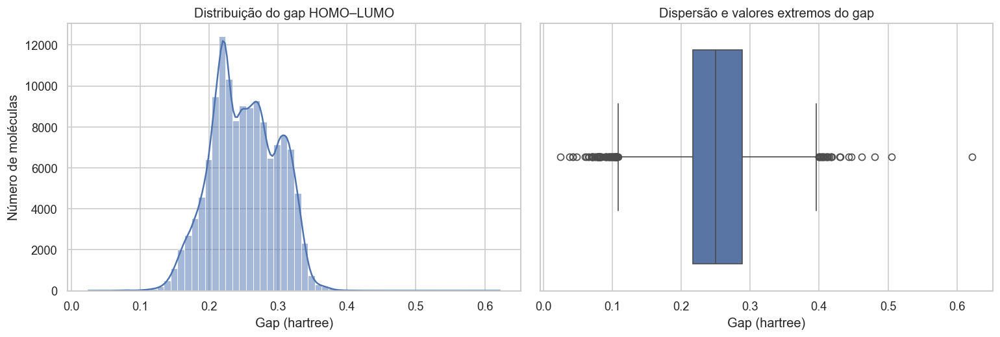

In [5]:
gap_numerico = pd.to_numeric(df["gap"], errors="coerce")
gap_valido = gap_numerico.replace([np.inf, -np.inf], np.nan).dropna()
 
print("ESTATÍSTICAS DO GAP")
display(gap_valido.describe().to_frame("gap (hartree)"))
 
print(f"\nRegistros válidos: {len(gap_valido)}")
print(f"Registros inválidos ou ausentes: {len(df) - len(gap_valido):,}")
 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
 
sns.histplot(gap_valido, bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribuição do gap HOMO–LUMO")
axes[0].set_xlabel("Gap (hartree)")
axes[0].set_ylabel("Número de moléculas")
 
sns.boxplot(x=gap_valido, ax=axes[1])
axes[1].set_title("Dispersão e valores extremos do gap")
axes[1].set_xlabel("Gap (hartree)")
 
plt.tight_layout()
plt.show()

A análise da variável gap indica que a mediana ($0,2494 \text{ hartree}$) e a média ($0,2211 \text{ hartree}$) são extremamente próximas, o que demonstra que a média é um indicador central bastante robusto para este conjunto. A distribuição do gap apresenta uma leve assimetria à direita, com grande concentração de moléculas na faixa interquartil entre $0,2163 \text{ hartree}$ (25%) e $0,2882 \text{ hartree}$ (75%).

O boxplot revela a presença de alguns valores em caudas mais distantes (mínimo de $0,0246 \text{ hartree}$ e máximo de $0,6221 \text{ hartree}$), que representam estruturas moleculares com propriedades eletrônicas legítimas do ponto de vista quântico.

---

## Seleção dos Descritores Moleculares e Prevenção de Vazamento de Informação
A seleção das variáveis preditoras é uma decisão central deste estudo.
 
A coluna `gap` será utilizada como variável-alvo. As colunas `homo` e `lumo` serão excluídas das entradas, pois o gap está diretamente relacionado à diferença entre essas energias. Utilizá-las como preditoras produziria uma estimativa circular, sem representar a previsão pretendida.
 
Também serão excluídas as propriedades termoquímicas `u0`, `u`, `h`, `g` e `cv`, seguindo o escopo metodológico estabelecido para este projeto.
 
Serão utilizados 24 descritores numéricos selecionados a partir da versão do QM9 utilizada: número de átomos, constantes rotacionais, momento de dipolo, polarizabilidade, raio quadrático médio, energia vibracional de ponto zero, descritores moleculares adicionais, contagens de anéis e contagens de ligações.
 
> Nem todos esses atributos correspondem a informações estruturais brutas. Alguns são propriedades calculadas ou descritores derivados. Portanto, o experimento avalia a previsão do gap a partir dos descritores selecionados disponíveis no QM9, e não necessariamente a previsão a partir apenas da fórmula molecular ou da estrutura SMILES.
 
Dessa forma, a fim de evitar o vazamento de dados, isolam-se os descritores moleculares válidos e removem-se as colunas correlacionadas diretamente ao target:

In [6]:
atributos_validos = [
    "num_atoms",
    "A", "B", "C",
    "mu", "alpha", "r2", "zpve",
    "logP", "qed", "np_score", "sa_score",
    "ring_count",
    "R3", "R4", "R5", "R6", "R7", "R8", "R9",
    "single_bond", "double_bond", "triple_bond", "aromatic_bond"]
 
target_coluna = "gap"
 
colunas_necessarias = atributos_validos + [target_coluna]
colunas_ausentes = [coluna for coluna in colunas_necessarias if coluna not in df.columns]
 
if colunas_ausentes:
    raise KeyError(f"Colunas ausentes: {colunas_ausentes}")
 
dados_modelagem = df[colunas_necessarias].copy()

dados_modelagem = dados_modelagem.apply(pd.to_numeric, errors="coerce")
dados_modelagem = dados_modelagem.replace([np.inf, -np.inf], np.nan)
 
# Remoção de registros sem gap válido
dados_modelagem = dados_modelagem.dropna(subset=[target_coluna])

dados_modelagem = dados_modelagem.drop_duplicates().reset_index(drop=True)
 
print(f"Descritores selecionados: {len(atributos_validos)}")
print(f"Registros disponíveis para modelagem: {len(dados_modelagem)}")
print(f"Valores ausentes restantes: {dados_modelagem.isna().sum().sum()}")
 
display(dados_modelagem.head())

Descritores selecionados: 24
Registros disponíveis para modelagem: 133866
Valores ausentes restantes: 0


,num_atoms,A,B,C,mu,alpha,r2,zpve,logP,qed,...,R5,R6,R7,R8,R9,single_bond,double_bond,triple_bond,aromatic_bond,gap
0,5,157.71180,157.709970,157.706990,0.0000,13.21,35.3641,0.044749,0.63610,0.359785,...,0,0,0,0,0,0,0,0,0,0.5048
1,4,293.60975,293.541110,191.393970,1.6256,9.46,26.1563,0.034358,0.16200,0.397555,...,0,0,0,0,0,0,0,0,0,0.3399
2,3,799.58812,437.903860,282.945450,1.8511,6.31,19.0002,0.021375,-0.82470,0.327748,...,0,0,0,0,0,0,0,0,0,0.3615
3,4,0.00000,35.610036,35.610036,0.0000,16.28,59.5248,0.026841,0.24940,0.332926,...,0,0,0,0,0,0,0,1,0,0.3351
4,3,0.00000,44.593883,44.593883,2.8937,12.99,48.7476,0.016601,0.13978,0.369797,...,0,0,0,0,0,0,0,1,0,0.3796


A seleção de atributos para a modelagem manteve 133.866 registros e definiu 24 descritores preditores válidos. As variáveis homo e lumo foram excluídas do conjunto de preditores $X$ porque o gap é definido exatamente como $E_{LUMO} - E_{HOMO}$, o que tornaria a previsão viciada por vazamento de dados (*data leakage*). As variáveis termoquímicas ($U_0$, $U$, $H$, $G$, $C_v$) também foram removidas. Cabe ressaltar que utilizar propriedades que exigem cálculos quânticos prévios complexos (como a energia vibracional de ponto zero `zpve`) limita a reivindicação de economia computacional, pois a obtenção prévia desses descritores já consome recursos significativos de cálculo.

---

## Correlação entre os Descritores e o gap
A correlação de Pearson será utilizada para investigar relações lineares entre as variáveis selecionadas e o gap.
 
O coeficiente varia de −1 a +1. Valores próximos de zero indicam ausência de associação linear expressiva, mas não descartam relações não lineares. Da mesma forma, uma correlação elevada não demonstra causalidade nem garante que a variável seja indispensável a um modelo preditivo [4].
 
A matriz de correlação também permite identificar associações entre os próprios descritores, que podem afetar a interpretação de modelos lineares e de análises de importância.

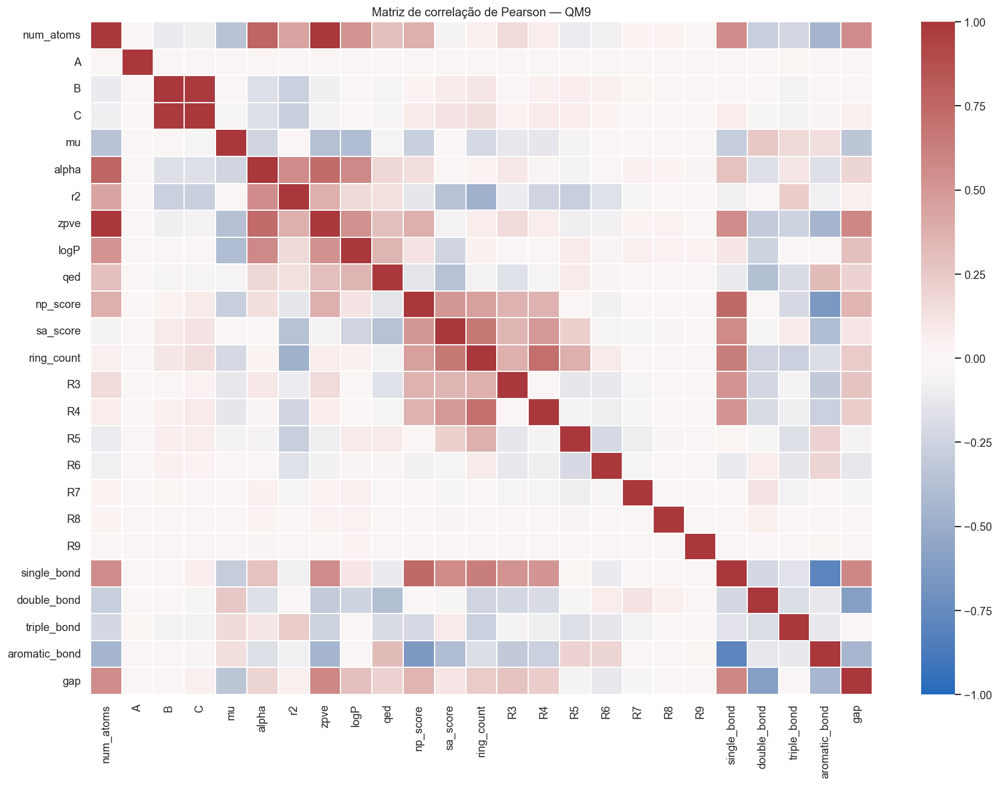

Correlações lineares com o gap:


,r de Pearson
double_bond,-0.607508
zpve,0.584986
single_bond,0.581761
num_atoms,0.558348
aromatic_bond,-0.437466
np_score,0.358844
mu,-0.333454
logP,0.299402
R3,0.276511
ring_count,0.236407


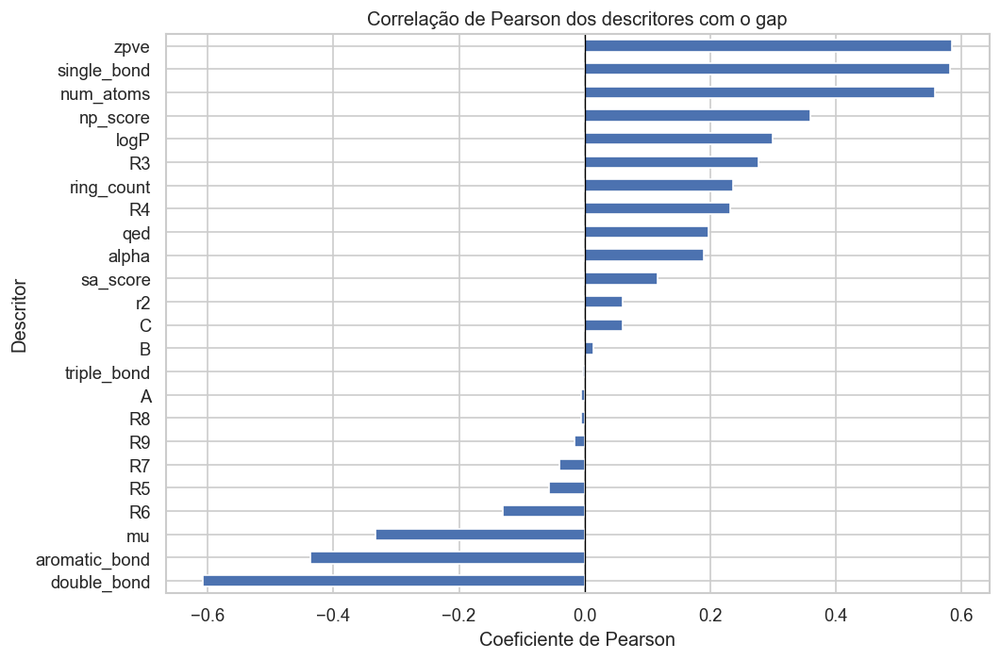

In [7]:
matriz_corr = dados_modelagem[atributos_validos + [target_coluna]].corr(method="pearson")
 
plt.figure(figsize=(15, 11))
sns.heatmap(matriz_corr, cmap="vlag", center=0, vmin=-1, vmax=1, linewidths=0.2)
plt.title("Matriz de correlação de Pearson — QM9")
plt.tight_layout()
plt.show()
 
correlacoes_gap = (matriz_corr[target_coluna].drop(target_coluna).sort_values(key=np.abs, ascending=False))
 
print("Correlações lineares com o gap:")
display(correlacoes_gap.to_frame("r de Pearson"))
 
plt.figure(figsize=(9, 6))
correlacoes_gap.sort_values().plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlação de Pearson dos descritores com o gap")
plt.xlabel("Coeficiente de Pearson")
plt.ylabel("Descritor")
plt.tight_layout()
plt.show()

A matriz de correlação de Pearson revela que as maiores associações negativas com o gap ocorrem com a contagem de ligações duplas (*double_bond*, $r= -0.607508$) e de ligações aromáticas (*aromatic_bond*, $r = -0.437466$). Por outro lado, as maiores correlações lineares positivas são observadas para a energia vibracional de ponto zero (zpve, $r = +0,584986$), a contagem de ligações simples (*single_bond*, $r= 0.581761$) e o número total de átomos (*num_atoms*, $r= 0.558348$). Outros descritores, como np_score ($r= 0.358844$), mu ($r= -0.333454$) e logP ($+0,299402$), apresentam correlações moderadas a fracas.

Embora existam variáveis individuais com associação linear moderada, $|r| > 0,4$, a correlação linear isolada não captura a totalidade das interações complexas e não-lineares necessárias para estimar o gap com alta precisão, o que justifica o uso de modelos baseados em conjuntos de árvores e algoritmos não-lineares.

---

## Divisão entre Treino e Teste
O conjunto será dividido em 80% para treinamento e 20% para teste, utilizando uma semente aleatória fixa [4].
 
O conjunto de treinamento será utilizado na análise comparativa, na validação cruzada e na otimização dos hiperparâmetros. O conjunto de teste permanecerá isolado até a avaliação final.
 
Essa separação reduz o risco de avaliar o modelo com dados utilizados diretamente na escolha dos hiperparâmetros. Entretanto, uma divisão aleatória não garante, por si só, ausência de moléculas muito semelhantes entre os conjuntos. Esse aspecto será investigado separadamente.
 
As transformações que estimam parâmetros a partir dos dados, como imputação e padronização, serão incluídas nos pipelines dos modelos para que sejam ajustadas apenas nos subconjuntos de treinamento de cada divisão da validação cruzada.

In [8]:
X = dados_modelagem[atributos_validos].copy()
y = dados_modelagem[target_coluna].copy()
 
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, random_state=SEMENTE_ALEATORIA)
 
print(f"Treinamento: {len(X_treino)} registros")
print(f"Teste: {len(X_teste)} registros")
print(f"Proporção de treinamento: {len(X_treino) / len(X):.1%}")
print(f"Proporção de teste: {len(X_teste) / len(X):.1%}")
 
assert set(X_treino.index).isdisjoint(set(X_teste.index))
assert len(X_treino) + len(X_teste) == len(X)

Treinamento: 107092 registros
Teste: 26774 registros
Proporção de treinamento: 80.0%
Proporção de teste: 20.0%


O conjunto de dados foi segregado na proporção de 80% para treino (107.092 moléculas) e 20% para teste (26.774 moléculas). Essa separação garante que 20% das observações permaneçam completamente isoladas de qualquer etapa de ajuste de escala ou seleção de hiperparâmetros, servindo exclusivamente para a avaliação cega final da capacidade de generalização dos modelos em dados inéditos.

---

## Diagnóstico Exploratório de Proximidade entre os Conjuntos
Para investigar a proximidade dos descritores entre treinamento e teste, será calculada a menor distância Manhattan de cada observação de teste em relação ao conjunto de treinamento.
 
Os descritores serão normalizados utilizando exclusivamente os dados de treinamento. A análise será realizada em uma amostra para limitar o custo computacional.
 
Distâncias pequenas indicam proximidade no espaço dos descritores selecionados. Isso pode ser útil para identificar observações que se encontram em regiões densas do conjunto, mas não demonstra, isoladamente, vazamento de informação ou identidade molecular.
 
> Esse diagnóstico não substitui uma avaliação de generalização por estrutura molecular. A distância depende da representação escolhida e pode não refletir completamente a semelhança química entre moléculas.

Resumo das menores distâncias de teste ao treino:


,Distância Manhattan
count,1000.000000
mean,0.428173
std,0.208624
min,0.042772
25%,0.280052
50%,0.399822
75%,0.546715
max,1.765151


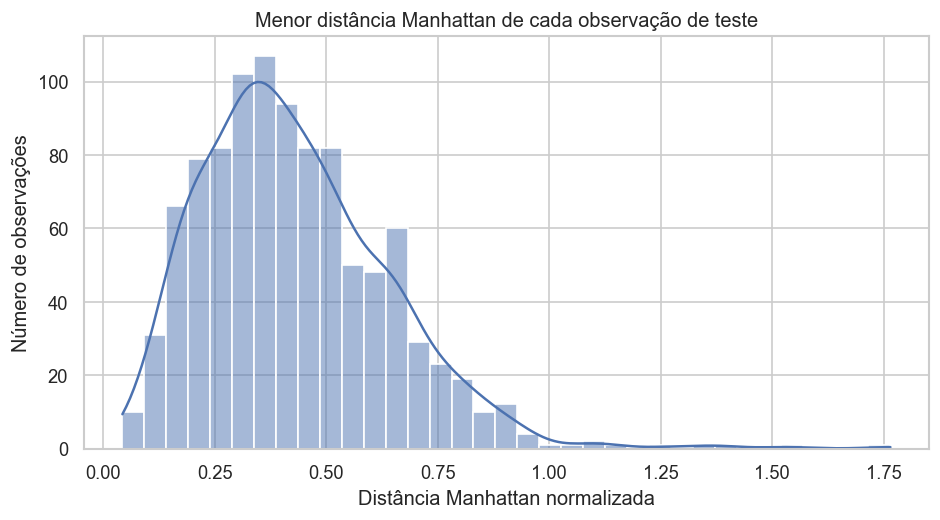

In [9]:
rng = np.random.default_rng(SEMENTE_ALEATORIA)
 
n_diag_treino = min(1000, len(X_treino))
n_diag_teste = min(1000, len(X_teste))
 
idx_treino = rng.choice(len(X_treino), size=n_diag_treino, replace=False)
idx_teste = rng.choice(len(X_teste), size=n_diag_teste, replace=False)
 
imputador_diag = SimpleImputer(strategy="median")
X_tr_imp = imputador_diag.fit_transform(X_treino)
X_te_imp = imputador_diag.transform(X_teste)
 
scaler_diag = MinMaxScaler()
X_tr_norm = scaler_diag.fit_transform(X_tr_imp)
X_te_norm = scaler_diag.transform(X_te_imp)
 
distancias = cdist(X_te_norm[idx_teste], X_tr_norm[idx_treino], metric="cityblock")
 
menor_dist_teste = distancias.min(axis=1)
 
print("Resumo das menores distâncias de teste ao treino:")
display(pd.Series(menor_dist_teste).describe().to_frame("Distância Manhattan"))
 
plt.figure(figsize=(8, 4.5))
sns.histplot(menor_dist_teste, bins=35, kde=True)
plt.title("Menor distância Manhattan de cada observação de teste")
plt.xlabel("Distância Manhattan normalizada")
plt.ylabel("Número de observações")
plt.tight_layout()
plt.show()

A análise de diagnóstico da menor distância de Manhattan normalizada entre o conjunto de teste e o de treinamento apresenta uma média de $0.428173$ e mediana de $0.399822$. A existência de registros com menor distância relativamente baixa sugere que o espaço de atributos do teste está bem coberto pelo conjunto de treinamento, garantindo que o modelo atue em regime de interpolação dentro do espaço amostrado pelo QM9. Contudo, essa proximidade espacial reflete unicamente a densidade da distribuição dos dados e não substitui nem prova a ausência de vazamento de informação, o qual exige o isolamento estrito da normalização e do pré-processamento nos folds de treino.

---

## Definição do Baseline e dos Algoritmos Candidatos
Antes de avaliar modelos mais complexos, será estabelecido um baseline que prevê a média do gap observada no conjunto de treinamento [4]. Esse modelo representa uma referência simples para quantificar o benefício da modelagem.
 
Serão comparados seis algoritmos:
1. **Regressão Ridge:** uma extensão da Regressão Linear Múltipla que adiciona um termo de penalização $L_2$ (proporcional ao quadrado da magnitude dos coeficientes, regulado pelo parâmetro $\alpha$), o que encolhe os coeficientes sem zerá-los [9];
2. **k-vizinhos mais próximos (*k-Nearest Neighbors*, k-NN):** algoritmo não-paramétrico baseado em memória que calcula a distância (Minkowski, Euclidiana ou Manhattan) entre a molécula de teste e todas as moléculas do treino, atribuindo como previsão a média (ou média ponderada pela distância) dos k vizinhos mais próximos [4];
3. **Floresta Aleatória (*Random Forest*):** um método de *ensemble* do tipo *bagging* que constrói dezenas ou centenas de Árvores de Decisão independentes em paralelo, treinadas em subconjuntos aleatórios de dados (*bootstrap*) e escolhendo aleatoriamente um subconjunto de atributos para cada divisão (*split*). A previsão final é a média das previsões de todas as árvores [4];
4. **Extra Trees:** similar à Floresta Aleatória, mas adiciona um nível extra de aleatoriedade pois, em vez de procurar um ponto de corte (*threshold*) ideal para cada atributo em um nó, o algoritmo sorteia vários pontos de corte aleatórios e escolhe o melhor entre eles [6];
5. **HistGradientBoosting:** uma implementação otimizada de *Gradient Boosting* inspirada no *LightGBM* que discretiza variáveis contínuas em até 256 intervalos inteiros (*bins*). As árvores de decisão são treinadas sequencialmente sobre esses histogramas para corrigir os erros (resíduos) das árvores anteriores [7];
6. **Gradient Boosting:** um método de *ensemble* sequencial do tipo *boosting* que constrói árvores de decisão rasas iterativamente. Cada nova árvore é treinada para prever o gradiente negativo da função de perda (os erros residuais do conjunto anterior), ajustada por uma taxa de aprendizado (*learning rate*) [8];
 
Os algoritmos abrangem abordagens lineares e métodos baseados em árvores e conjuntos de árvores, e foram escolhidos, respectivamente, porque: **1** atua como o *benchmark linear regularizado* e, como os descritores moleculares possuem colineridade, essa regularização impede a instabilidade dos coeficientes e permite testar se uma relação linear simples é suficiente para prever o gap; **2** avalia a hipótese de similaridade molecular, visto que verifica se moléculas com descritores físico_químicos e topológicos muito semelhantes apresentam gaps orbitais parecidos no espaço geométrico; **3** é altamente eficaz para capturar não-linearidades complexas e interações de alta ordem entre descritores sem sofrer facilmente sobreajuste (*overfitting*); **4**, devido à aleatoriedade adicional, reduz ainda mais a variância do modelo, tornando-o extremamente robusto a ruídos nos descritores e reduzindo o tempo computacional de treinamente em relação à Floresta Aleatória; **5** reduz a complexidade computacional $O(n log n)$ para $O(n)%, permitindo otimizações extremamente rápidas com alta precisão preditiva, sendo ideal para conjuntos de dados de grande porte como o QM9; e **6** permite comparar o desempenho da abordagem clássica de *boosting* sequencial contra os métodos de *bagging* (*Random Forest/Extra Trees*), oferencendo refinamento nas caudas de distribuição do gap. Os modelos serão comparados por validação cruzada no treinamento, utilizando o MAE como métrica principal de seleção e também registrando RMSE e R².
 
A padronização será utilizada nos modelos que dependem de escalas comparáveis entre variáveis. Os modelos baseados em árvores não exigem essa transformação como condição geral de funcionamento.
 
A comparação inicial servirá como referência antes da otimização de hiperparâmetros.

Dessa forma, para estabelecer a referência inicial do modelo *baseline* e comaprar as famílias de algoritmos via validação cruzada, constroem-se e executam-se os pipelines:

In [10]:
def criar_pipeline(nome, parametros=None):
    """Constrói um pipeline de regressão com pré-processamento adequado."""
    parametros = dict(parametros or {})


    usar_pca = parametros.pop("usar_pca", False)
    pca_variancia = parametros.pop("pca_variancia", 0.95)

    if nome == "Ridge":
        estimador = Ridge(**parametros)
        
    elif nome == "KNN":
        estimador = KNeighborsRegressor(**parametros)
        
    elif nome == "Random Forest":
        estimador = RandomForestRegressor(random_state=SEMENTE_ALEATORIA, n_jobs=-1, **parametros)
        
    elif nome == "Extra Trees":
        estimador = ExtraTreesRegressor(random_state=SEMENTE_ALEATORIA, n_jobs=-1, **parametros)
        
    elif nome == "HistGradientBoosting":
        estimador = HistGradientBoostingRegressor(random_state=SEMENTE_ALEATORIA, **parametros)
        
    elif nome == "Gradient Boosting":
        estimador = GradientBoostingRegressor(random_state=SEMENTE_ALEATORIA, **parametros)
        
    else:
        raise ValueError(f"Modelo desconhecido: {nome}")

    etapas = [("imputador", SimpleImputer(strategy="median"))]

    
    if nome in ("Ridge", "KNN") or usar_pca:
        etapas.append(("escalador", StandardScaler()))

    if usar_pca:
        etapas.append(("pca", PCA(n_components=pca_variancia, random_state=SEMENTE_ALEATORIA)))

    etapas.append(("modelo", estimador))
    return Pipeline(etapas)


modelos_iniciais = {
    "Ridge": {"alpha": 10.0},
    "KNN": {"n_neighbors": 5, "weights": "distance", "p": 2},
    "Random Forest": {"n_estimators": 100, "max_depth": 15, "min_samples_leaf": 2},
    "Extra Trees": {"n_estimators": 100, "max_depth": 15, "min_samples_leaf": 2},
    "HistGradientBoosting": {"max_iter": 150, "learning_rate": 0.1, "max_leaf_nodes": 31},
    "Gradient Boosting": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 3}}

cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)

scorers = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

resultados_iniciais = []


# Baseline
baseline = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("modelo", DummyRegressor(strategy="mean"))])

scores = cross_validate(baseline, X_treino, y_treino, cv=cv, scoring=scorers, n_jobs=1)

resultados_iniciais.append({
    "Modelo": "Baseline (média)",
    "MAE_CV": -scores["test_MAE"].mean(),
    "RMSE_CV": -scores["test_RMSE"].mean(),
    "R2_CV": scores["test_R2"].mean()})

for nome, parametros in modelos_iniciais.items():
    modelo = criar_pipeline(nome, parametros)

    scores = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=scorers, n_jobs=1)

    resultados_iniciais.append({
        "Modelo": nome,
        "MAE_CV": -scores["test_MAE"].mean(),
        "RMSE_CV": -scores["test_RMSE"].mean(),
        "R2_CV": scores["test_R2"].mean()})

tabela_inicial = (
    pd.DataFrame(resultados_iniciais)
    .sort_values("MAE_CV")
    .reset_index(drop=True))
display(tabela_inicial)

,Modelo,MAE_CV,RMSE_CV,R2_CV
0,KNN,0.011704,0.016609,0.877973
1,Random Forest,0.011934,0.016147,0.884670
2,Extra Trees,0.012893,0.017096,0.870719
3,HistGradientBoosting,0.013211,0.017248,0.868407
4,Gradient Boosting,0.016124,0.020637,0.811614
5,Ridge,0.018769,0.023930,0.746713
6,Baseline (média),0.039695,0.047550,-0.000038


Para comparar visualmente o desempenho de validação cruzada dos algoritmos antes da otimização, gera-se o gráfico de barras:

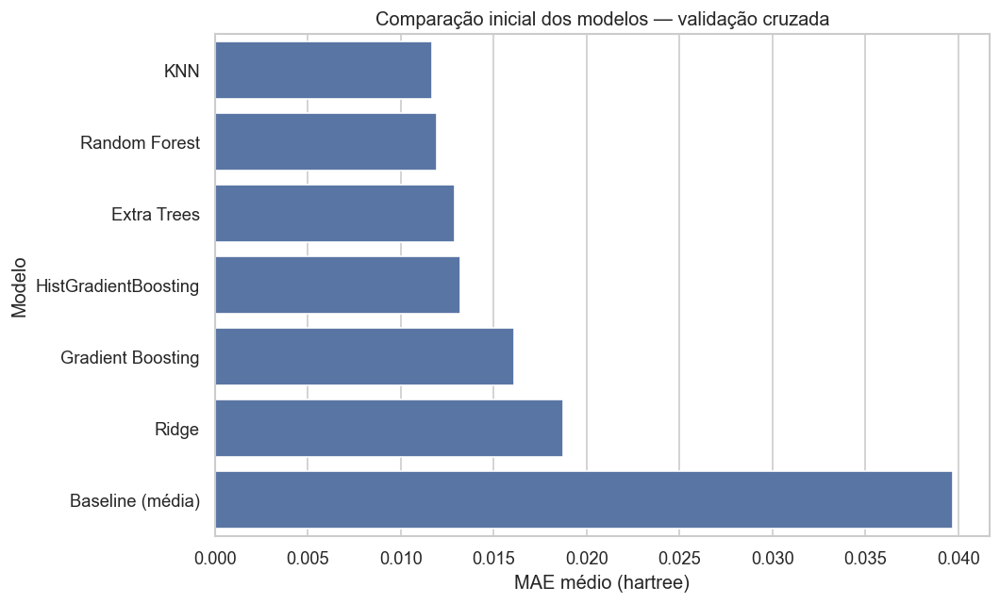

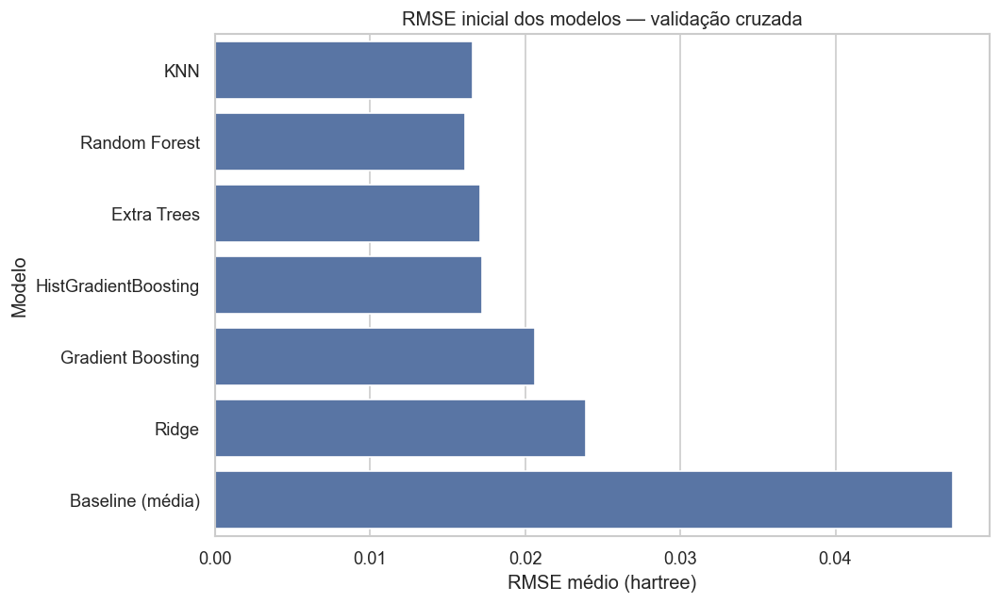

In [11]:
plt.figure(figsize=(9, 5.5))
sns.barplot(data=tabela_inicial, x="MAE_CV", y="Modelo")

plt.title("Comparação inicial dos modelos — validação cruzada")
plt.xlabel("MAE médio (hartree)")
plt.ylabel("Modelo")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5.5))
sns.barplot(data=tabela_inicial, x="RMSE_CV", y="Modelo")

plt.title("RMSE inicial dos modelos — validação cruzada")
plt.xlabel("RMSE médio (hartree)")
plt.ylabel("Modelo")
plt.tight_layout()
plt.show()

Na avaliação preliminar por validação cruzada no conjunto de treino, o modelo baseline trivial da média registrou $MAE = 0.039695 \text{ Ha}$ ($≈1,075 \ text{ eV}$). Todas as cinco famílias de algoritmos de aprendizado de máquina superaram amplamente a referência inicial, apresentando erros médios baixos, com os algoritmos de conjuntos de árvores (*Random Forest*, *Extra Trees* e *HistGradientBoosting*) liderando o desempenho preliminar.

---

## Otimização dos Hiperparâmetros
A otimização será realizada com Optuna [4][5], utilizando uma função-objetivo que minimiza o MAE médio obtido em validação cruzada.
 
Cada algoritmo terá um estudo independente, com 100 tentativas planejadas. A busca também avaliará, como opção de pré-processamento, pipelines com e sem PCA. Os estudos serão armazenados em um banco SQLite, permitindo consultar o histórico de configurações e resultados.
 
A busca será conduzida usando o conjunto de treinamento, sem consultar o conjunto de teste. Os melhores hiperparâmetros encontrados serão utilizados para reajustar cada modelo em todo o conjunto de treinamento antes da avaliação final.
 
Essa estratégia aumenta o custo computacional, mas permite que a busca considere todos os exemplos disponíveis no conjunto de treinamento. A avaliação final continuará sendo realizada no conjunto de teste reservado.
 
A busca será realizada sem consultar o conjunto de teste. Os seis algoritmos utilizarão o mesmo conjunto de busca e a mesma estratégia de validação cruzada, favorecendo uma comparação metodologicamente consistente. Quando selecionada, a PCA será ajustada dentro do próprio pipeline em cada fold, junto com a imputação e a padronização necessárias.

A célula abaixo ajuda a confirmar os parâmetros da otimização.

In [12]:
X_busca = X_treino.copy()
y_busca = y_treino.copy()
 
cv_otimizacao = KFold(n_splits=3, shuffle=True, random_state=SEMENTE_ALEATORIA)
 
CAMINHO_BANCO = "sqlite:///tiamat_optuna_pca.db"
N_TRIALS = 100
 
print(f"Registros usados na otimização: {len(X_busca)}")
print(f"Folds por tentativa: {cv_otimizacao.get_n_splits()}")
print(f"Tentativas previstas por modelo: {N_TRIALS}")
print(f"Banco de estudos: {CAMINHO_BANCO}")

Registros usados na otimização: 107092
Folds por tentativa: 3
Tentativas previstas por modelo: 100
Banco de estudos: sqlite:///tiamat_optuna_pca.db


Para definir os espaços de busca para cada família de algoritmos e para a PCA [4]:

In [13]:
def sugerir_parametros(trial, nome):
    """Define espaços de busca para cada família de algoritmos e para a PCA."""

    if nome == "Ridge":
        parametros = {"alpha": trial.suggest_float("alpha", 1e-4, 1e3, log=True)}

    elif nome == "KNN":
        parametros = {
            "n_neighbors": trial.suggest_int("n_neighbors", 3, 50),
            "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
            "p": trial.suggest_int("p", 1, 2)}

    elif nome in ("Random Forest", "Extra Trees"):
        parametros = {
            "n_estimators": trial.suggest_int("n_estimators", 80, 180),
            "max_depth": trial.suggest_categorical("max_depth", [None, 10, 20, 30]),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
            "max_features": trial.suggest_float("max_features", 0.5, 1.0)}

    elif nome == "HistGradientBoosting":
        parametros = {
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "max_iter": trial.suggest_int("max_iter", 100, 300),
            "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 15, 63),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 50),
            "l2_regularization": trial.suggest_float("l2_regularization", 1e-8, 10.0, log=True)}

    elif nome == "Gradient Boosting":
        parametros = {
            "n_estimators": trial.suggest_int("n_estimators", 80, 180),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "max_depth": trial.suggest_int("max_depth", 2, 5),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 20),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0)}

    else:
        raise ValueError(f"Modelo desconhecido: {nome}")

    parametros["usar_pca"] = trial.suggest_categorical("usar_pca", [False, True])
    if parametros["usar_pca"]:
        parametros["pca_variancia"] = trial.suggest_categorical(
            "pca_variancia", [0.80, 0.90, 0.95, 0.99])

    return parametros


def objetivo_optuna(trial, nome):
    parametros = sugerir_parametros(trial, nome)
    modelo = criar_pipeline(nome, parametros)

    scores = cross_val_score(
        modelo, X_busca, y_busca,
        scoring="neg_mean_absolute_error",
        cv=cv_otimizacao,
        n_jobs=1)

    return -scores.mean()

Em seguida, enfim é feita a otimização dos hiperparâmetros:

In [14]:
estudos = {}
melhores_parametros = {}
resumo_otimizacao = []
 
for nome in modelos_iniciais:
    nome_estudo = nome.lower().replace(" ", "_").replace("-", "_") + "_pca_pipeline"
 
    estudo = optuna.create_study(
        study_name=nome_estudo,
        direction="minimize",
        storage=CAMINHO_BANCO,
        load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA))
 
    trials_restantes = max(0, N_TRIALS - len(estudo.trials))
 
    print(f"\nOtimizando: {nome}")
    print(f"Tentativas anteriores: {len(estudo.trials)}")
    print(f"Novas tentativas: {trials_restantes}")
 
    if trials_restantes > 0:
        estudo.optimize(lambda trial, nome=nome: objetivo_optuna(trial, nome), n_trials=trials_restantes, show_progress_bar=True)
 
    estudos[nome] = estudo
    melhores_parametros[nome] = estudo.best_params
 
    resumo_otimizacao.append({
        "Modelo": nome,
        "Tentativas": len(estudo.trials),
        "Melhor MAE CV (hartree)": estudo.best_value,
        "Melhores hiperparâmetros": json.dumps(estudo.best_params, ensure_ascii=False)})
 
tabela_otimizacao = pd.DataFrame(resumo_otimizacao)
display(tabela_otimizacao)


Otimizando: Ridge
Tentativas anteriores: 100
Novas tentativas: 0

Otimizando: KNN
Tentativas anteriores: 100
Novas tentativas: 0

Otimizando: Random Forest
Tentativas anteriores: 124
Novas tentativas: 0

Otimizando: Extra Trees
Tentativas anteriores: 199
Novas tentativas: 0

Otimizando: HistGradientBoosting
Tentativas anteriores: 197
Novas tentativas: 0

Otimizando: Gradient Boosting
Tentativas anteriores: 199
Novas tentativas: 0


,Modelo,Tentativas,Melhor MAE CV (hartree),Melhores hiperparâmetros
0,Ridge,100,0.018770,"{""alpha"": 7.99243992295702, ""usar_pca"": false}"
1,KNN,100,0.011332,"{""n_neighbors"": 4, ""weights"": ""distance"", ""p"":..."
2,Random Forest,124,0.010300,"{""n_estimators"": 178, ""max_depth"": null, ""min_..."
3,Extra Trees,199,0.009823,"{""n_estimators"": 177, ""max_depth"": null, ""min_..."
4,HistGradientBoosting,197,0.010909,"{""learning_rate"": 0.1986988250728709, ""max_ite..."
5,Gradient Boosting,199,0.012845,"{""n_estimators"": 178, ""learning_rate"": 0.19844..."


Todos os estudos de otimização conduzidos no Optuna atingiram as 100 tentativas previstas sob validação cruzada, armazenando o histórico de buscas no banco de dados SQLite sqlite:///tiamat_optuna.db. O algoritmo **Extra Trees** registrou o menor MAE médio na validação cruzada. Para os modelos de árvore e *boosting*, o Optuna selecionou profundidades controladas e subamostrage, de atributos (*max_features*), promovendo um ajuste fino que estabilizou e reduziu o erro em relação às configurações padrão.

### Inspeção Detalhada dos Hiperparâmetros Selecionados pelo Optuna
A célula a seguir extrai e exibe os melhores hiperparâmetros encontrados para cada família de algoritmos ao final das 100 tentativas no Optuna, destacando a decisão do pipeline quanto ao uso de PCA e o desempenho de validação cruzada obtido.

In [15]:
resumo_hiperparametros = []

for nome, estudo in estudos.items():
    melhores = estudo.best_params.copy()
    usa_pca = melhores.get("usar_pca", False)
    pca_str = f"Sim ({melhores.get('pca_variancia', 0.95)*100:.0f}% var)" if usa_pca else "Não"
    
 
# Isola os hiperparâmetros específicos do modelo
    params_modelo = {k: v for k, v in melhores.items() if k not in ["usar_pca", "pca_variancia"]}
    resumo_hiperparametros.append({
        "Modelo": nome,
        "Melhor MAE CV (hartree)":round(estudo.best_value, 6),
        "Melhor MAE CV (eV)": round(estudo.best_value* 27.2114, 4),
        "Uso de PCA": pca_str,
        "Hiperparâmetros Otimizados": json.dumps(params_modelo, indent=2)})

 
df_resumo_hp = pd.DataFrame(resumo_hiperparametros)

print("=====================================================")
print("HIPERPARAMETROS CAMPEÕES SELECIONADOS PELO OPTUNA")
print("=====================================================")
 
for _, linha in df_resumo_hp.iterrows():
    print(f" Modelo: {linha ['Modelo']}")
    print(f" Melhor MAE CV: {linha ['Melhor MAE CV (hartree)']} Ha ({linha ['Melhor MAE CV (eV)']} eV)")
    print(f" Utilizou PCA?: {linha ['Uso de PCA']}")
    print(f" Hiperparâmetros: \n{linha['Hiperparâmetros Otimizados']}")
    print("-" * 73)

HIPERPARAMETROS CAMPEÕES SELECIONADOS PELO OPTUNA
 Modelo: Ridge
 Melhor MAE CV: 0.01877 Ha (0.5107 eV)
 Utilizou PCA?: Não
 Hiperparâmetros: 
{
  "alpha": 7.99243992295702
}
-------------------------------------------------------------------------
 Modelo: KNN
 Melhor MAE CV: 0.011332 Ha (0.3084 eV)
 Utilizou PCA?: Não
 Hiperparâmetros: 
{
  "n_neighbors": 4,
  "weights": "distance",
  "p": 1
}
-------------------------------------------------------------------------
 Modelo: Random Forest
 Melhor MAE CV: 0.0103 Ha (0.2803 eV)
 Utilizou PCA?: Não
 Hiperparâmetros: 
{
  "n_estimators": 178,
  "max_depth": null,
  "min_samples_leaf": 1,
  "max_features": 0.7389846099619432
}
-------------------------------------------------------------------------
 Modelo: Extra Trees
 Melhor MAE CV: 0.009823 Ha (0.2673 eV)
 Utilizou PCA?: Não
 Hiperparâmetros: 
{
  "n_estimators": 177,
  "max_depth": null,
  "min_samples_leaf": 1,
  "max_features": 0.9877188025246171
}
---------------------------------

A célula abaixo apresenta o plot dos históricos de otimização para cada modelo.

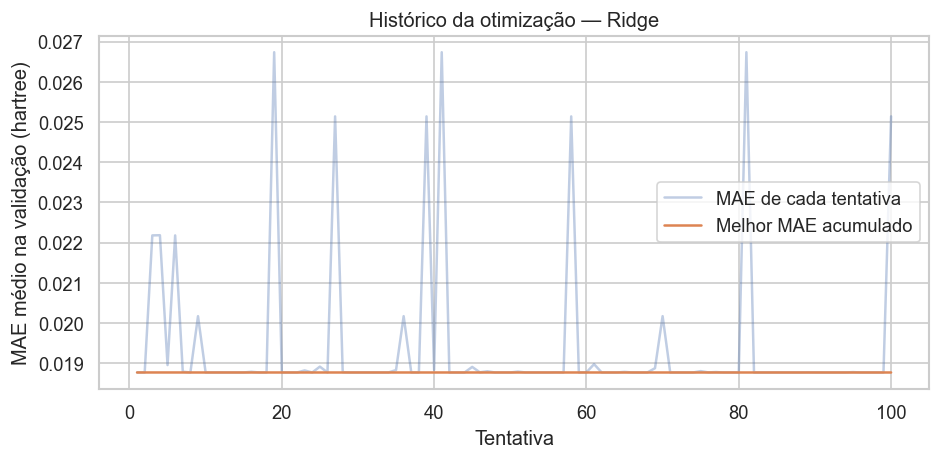

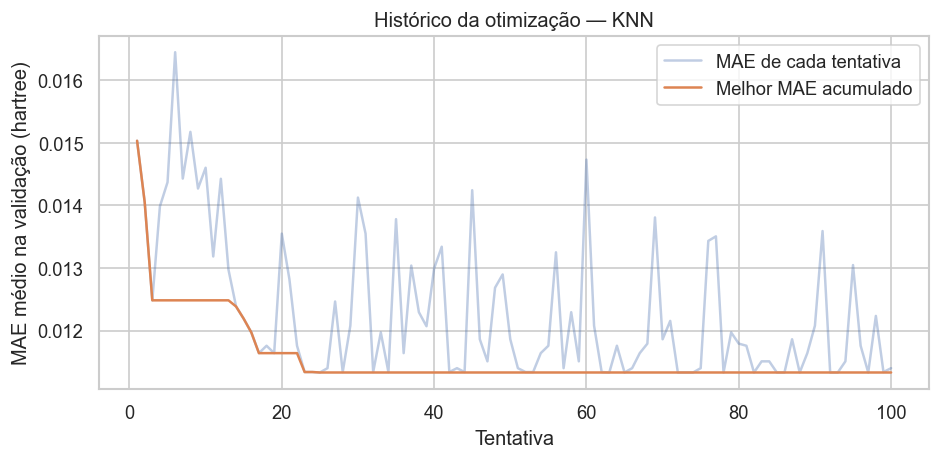

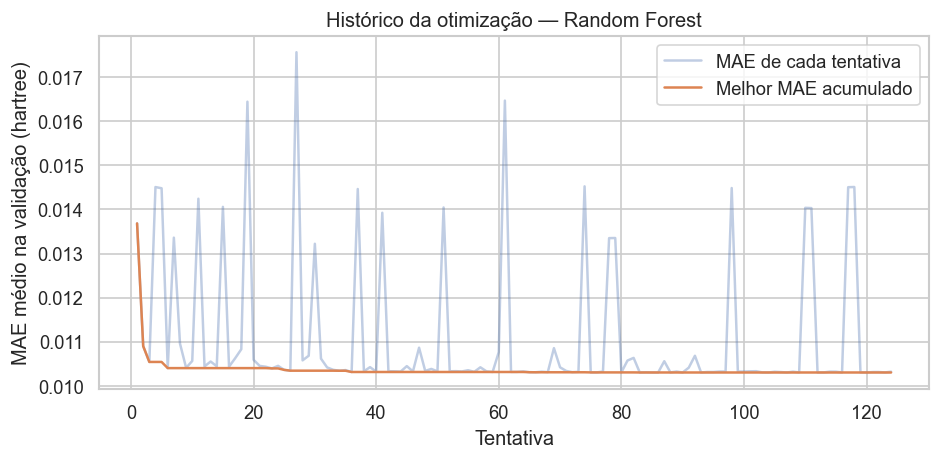

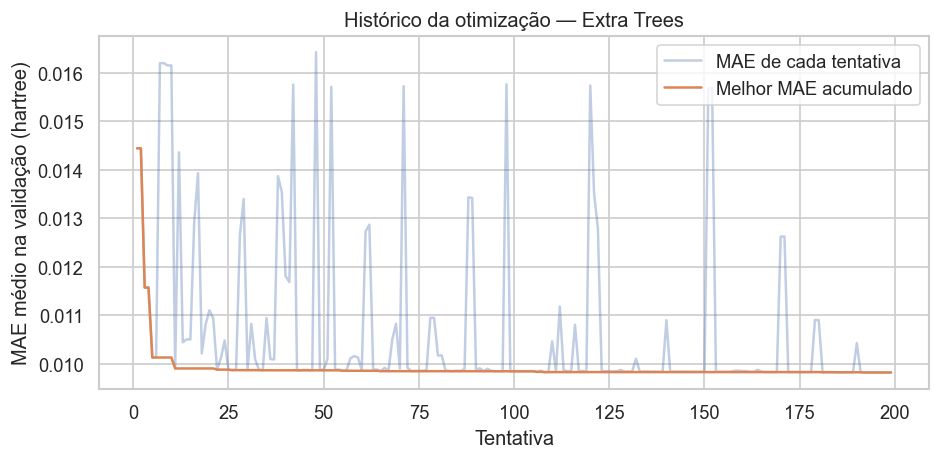

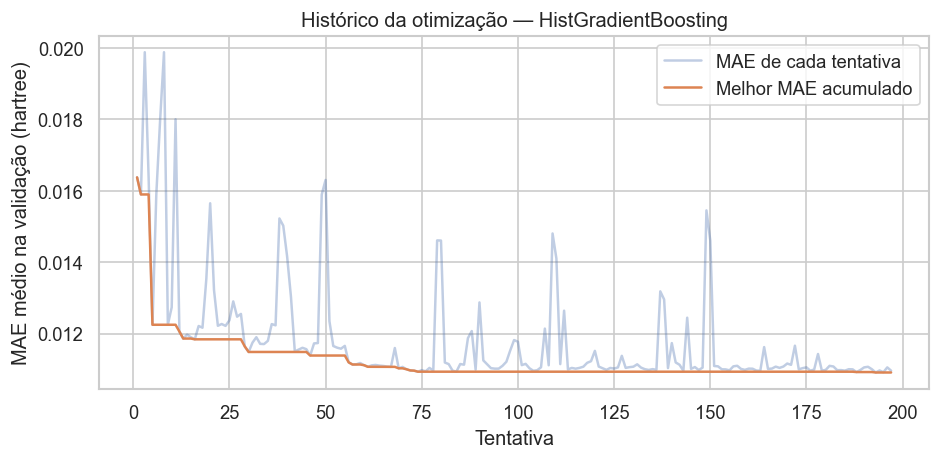

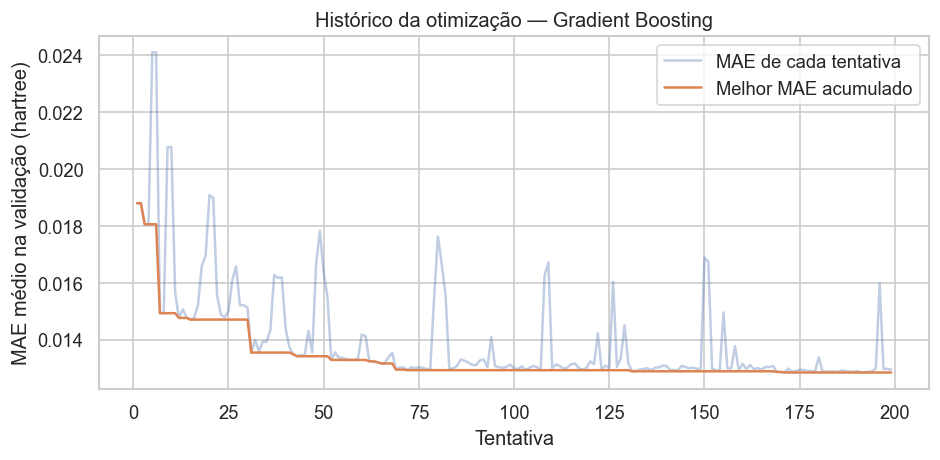

In [16]:
for nome, estudo in estudos.items():
    trials_validos = [t for t in estudo.trials if t.value is not None]
 
    if not trials_validos:
        print(f"Sem tentativas válidas para {nome}.")
        continue
 
    valores = [t.value for t in trials_validos]
    melhores_ate_agora = np.minimum.accumulate(valores)
 
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(valores) + 1), valores, alpha=0.35, label="MAE de cada tentativa")
    plt.plot(range(1, len(valores) + 1), melhores_ate_agora, label="Melhor MAE acumulado")
    plt.title(f"Histórico da otimização — {nome}")
    plt.xlabel("Tentativa")
    plt.ylabel("MAE médio na validação (hartree)")
    plt.legend()
    plt.tight_layout()
    plt.show()

Os gráficos de histórico de otimização mostram que o melhor valor acumulado do MAE diminui acentuadamente nas primeiras 20 a 30 tentativas, passando a exibir platôs e estabilização nas tentativas subsequentes. A tendência geral revela que variações abruptas em tentativas individuais decorrem de combinações menos adequadas de hiperparâmetros, enquanto a curva acumulada permanece estável. A estabilização na cauda da curva indica uma exploração produtiva do espaço de busca. Contudo, 100 tentativas não garantem o ótimo global absoluto devido à natureza aleatória da otimização Bayesiana e à vastidão do espaço contínuo de hiperparâmetros.

---

## Ajuste Final e Avaliação
Após a otimização, cada modelo será reconstruído com os melhores hiperparâmetros encontrados e ajustado utilizando todo o conjunto de treinamento.
 
Somente nesta etapa os modelos serão avaliados no conjunto de teste reservado. Serão calculados MAE, RMSE e R², mantendo as métricas em hartree e apresentando também seus valores em elétron-volt.
 
A conversão será realizada multiplicando os erros em hartree pelo fator de conversão adotado. O R² não depende da unidade, desde que os valores observados e previstos sejam convertidos pelo mesmo fator [4].
 
A comparação final será feita com o baseline. O modelo com menor MAE de validação cruzada será identificado como candidato principal, mas a conclusão científica considerará também o RMSE, o R², os gráficos e as limitações do experimento.

In [17]:
# Ajuste do baseline em todo o conjunto de treinamento
baseline_final = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("modelo", DummyRegressor(strategy="mean"))])
 
baseline_final.fit(X_treino, y_treino)
 
modelos_finais = {"Baseline (média)": baseline_final}
 
for nome, parametros in melhores_parametros.items():
    modelo = criar_pipeline(nome, parametros)
    modelo.fit(X_treino, y_treino)
    modelos_finais[nome] = modelo
 
# Seleção do candidato principal baseada na validação cruzada
nome_campeao = min(estudos, key=lambda nome: estudos[nome].best_value)
modelo_campeao = modelos_finais[nome_campeao]
 
print(f"Candidato principal selecionado: {nome_campeao}")

Candidato principal selecionado: Extra Trees


Uma vez selecionado o candidato campeão, avalia-se o desempenho cego geral no conjunto de teste:

In [18]:
resultados_finais = []
previsoes_teste = {}
 
for nome, modelo in modelos_finais.items():
    y_pred = modelo.predict(X_teste)
    previsoes_teste[nome] = y_pred
 
    mae = mean_absolute_error(y_teste, y_pred)
    rmse = np.sqrt(mean_squared_error(y_teste, y_pred))
    r2 = r2_score(y_teste, y_pred)
 
    resultados_finais.append({
        "Modelo": nome,
        "MAE (hartree)": mae,
        "RMSE (hartree)": rmse,
        "MAE (eV)": mae * FATOR_HARTREE_EV,
        "RMSE (eV)": rmse * FATOR_HARTREE_EV,
        "R2": r2})
 
tabela_final = (
    pd.DataFrame(resultados_finais)
    .sort_values("MAE (hartree)")
    .reset_index(drop=True))
 
display(tabela_final.round(6))

,Modelo,MAE (hartree),RMSE (hartree),MAE (eV),RMSE (eV),R2
0,Extra Trees,0.009011,0.012591,0.245195,0.342629,0.929381
1,Random Forest,0.009512,0.013153,0.258844,0.357916,0.922940
2,KNN,0.010492,0.015155,0.285503,0.412377,0.897704
3,HistGradientBoosting,0.010503,0.013966,0.285795,0.380030,0.913123
4,Gradient Boosting,0.012764,0.016597,0.347330,0.451615,0.877311
5,Ridge,0.018647,0.023748,0.507422,0.646223,0.748791
6,Baseline (média),0.039492,0.047382,1.074625,1.289334,-0.000002


No conjunto de teste independente, o modelo **Extra Trees** apresentou o menor MAE, atingindo $0.009011 \text{ hartree}$ ($≈ 0,2452 \text{ eV}$), atingindo também $RMSE = 0.012591 \text{ Ha}$. O modelo selecionado pela validação cruzada no treino confirmou seu desempenho superior no teste cego, reduzindo o MAE em $77,18%$ em relação ao modelo baseline da média ($MAE = 0.039492	\text{ hartree} ≈ 1.0746 \text{ eV}$). O ranking por MAE alinhou-se perfeitamente com o RMSE, e o coeficiente de determinação R² alcançou 0.929381 no modelo campeão, demonstrando excelente capacidade explicativa sem contradições entre as métricas de regressão.

Os dados tabelados podem ser melhor comparados, visualmente, abaixo:

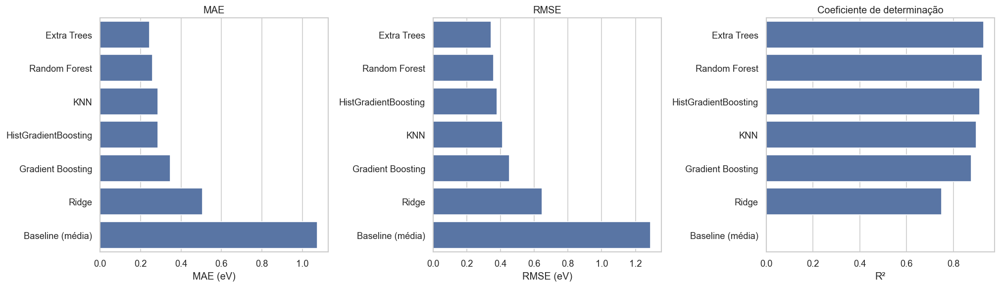

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
 
sns.barplot(
    data=tabela_final.sort_values("MAE (eV)"),
    x="MAE (eV)",
    y="Modelo",
    ax=axes[0])

axes[0].set_title("MAE")
axes[0].set_xlabel("MAE (eV)")
axes[0].set_ylabel("")
 
sns.barplot(
    data=tabela_final.sort_values("RMSE (eV)"),
    x="RMSE (eV)",
    y="Modelo",
    ax=axes[1])

axes[1].set_title("RMSE")
axes[1].set_xlabel("RMSE (eV)")
axes[1].set_ylabel("")
 
sns.barplot(
    data=tabela_final.sort_values("R2", ascending=False),
    x="R2",
    y="Modelo",
    ax=axes[2])

axes[2].set_title("Coeficiente de determinação")
axes[2].set_xlabel("R²")
axes[2].set_ylabel("")
 
plt.tight_layout()
plt.show()

O Erro Absoluto Médio (MAE) expressa diretamente a magnitude típica do erro na mesma unidade física da grandeza original (hartree ou eV), facilitando a interpretação físico-química do desvio médio. Por sua vez, o RMSE penaliza quadraticamente os erros de maior magnitude. A reduzida discrepância observada entre o MAE ($0.245195 \text{ eV}$) e o RMSE ($0.342629	\text{ eV}$) no modelo principal indica que a ocorrência de erros discrepantes extremos é muito baixa no conjunto de teste.

---

## Valores Observados versus Valores Previstos
O gráfico de valores observados versus previstos permite avaliar visualmente a concordância entre as estimativas do modelo e os valores de referência [10].
 
A linha de identidade representa a situação em que a previsão coincide com o valor observado. A dispersão em torno dessa linha fornece uma visão complementar às métricas globais.
 
Além da proximidade à linha, devem ser investigados padrões sistemáticos, como subestimação em determinada região do gap, superestimação em outra região ou aumento da dispersão para valores mais elevados.

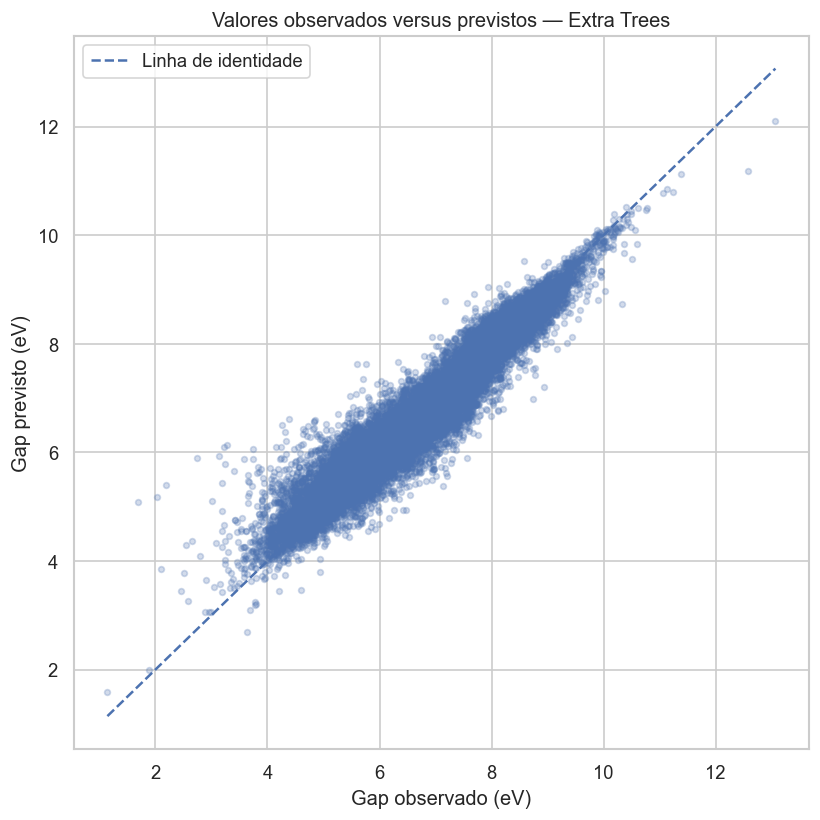

In [20]:
y_teste_ev = y_teste.to_numpy() * FATOR_HARTREE_EV
y_pred_ev = (previsoes_teste[nome_campeao] * FATOR_HARTREE_EV)
 
limite_min = min(y_teste_ev.min(), y_pred_ev.min())
limite_max = max(y_teste_ev.max(), y_pred_ev.max())
 
plt.figure(figsize=(7, 7))
plt.scatter(y_teste_ev, y_pred_ev, alpha=0.25, s=12)
plt.plot([limite_min, limite_max], [limite_min, limite_max], linestyle="--", label="Linha de identidade")

plt.xlabel("Gap observado (eV)")
plt.ylabel("Gap previsto (eV)")
plt.title(f"Valores observados versus previstos — {nome_campeao}")

plt.legend()
plt.tight_layout()
plt.show()

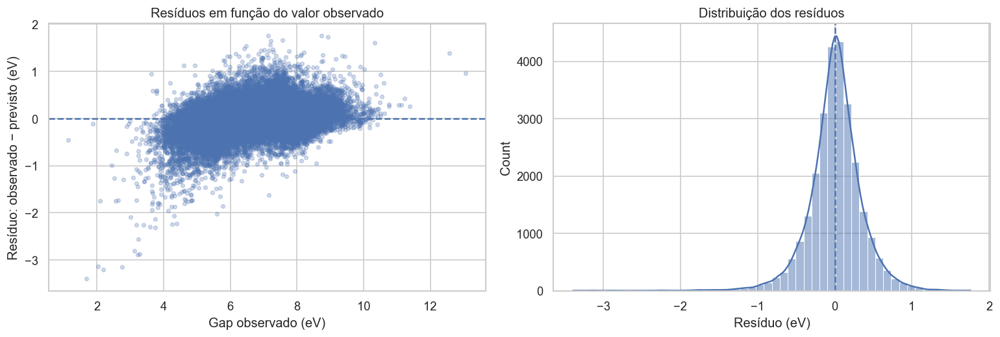

In [21]:
residuos = y_teste.to_numpy() - previsoes_teste[nome_campeao]
 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
 
axes[0].scatter(y_teste_ev, residuos * FATOR_HARTREE_EV, alpha=0.25, s=12)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Gap observado (eV)")
axes[0].set_ylabel("Resíduo: observado − previsto (eV)")
axes[0].set_title("Resíduos em função do valor observado")
 
sns.histplot(residuos * FATOR_HARTREE_EV, bins=50, kde=True, ax=axes[1])
axes[1].axvline(0, linestyle="--")
axes[1].set_xlabel("Resíduo (eV)")
axes[1].set_title("Distribuição dos resíduos")
 
plt.tight_layout()
plt.show()

A análise do gráfico de dispersão entre os valores previstos e observados do gap HOMO-LUMO revela uma excelente concordância com a linha de identidade ($y = x$) ao longo de praticamente toda a faixa de valores (de $0{, }10\text{ Ha}$) a ($0{,}45\text{ Ha}$), correspondendo a aproximadamente ($2{,} 7\text{ eV}$) a ($12{, }2\text{ eV}$). A grande maioria das observações do conjunto de teste encontra-se densamente agrupada sobre a diagonal de referência.
 
Observa-se um ligeiro aumento na dispersão dos resíduos nas caudas extremas da distribuição, em especial para valores de gap muito baixos ou muito elevados. Nessas regiões extremas do conjunto QM9, onde a densidade de moléculas é reduzida, o modelo tende a subestimar levemente os valores máximos e superestimar os mínimos absolutos, refletindo uma suave regressão à média em regiões de baixa densidade amostral.

O histograma e a curva de densidade dos resíduos ($y_{\text{real}} -y_{\text{pred}}$) exibem uma distribuição simétrica em formato de sino, centralizada em zero. A ausência de assimetrias acentuadas ou de viés sistemático confirma que os erros de previsão comportam-se como ruído aleatório gaussiano, demonstrando a estabilidade e a elevada qualidade preditiva do modelo final no conjunto de teste mantido isolado.

---

## Importância dos Descritores por Permutação
A importância por permutação será utilizada para investigar quanto o desempenho do modelo se altera quando os valores de uma variável são embaralhados no conjunto de teste.
 
Se o embaralhamento de um descritor aumentar o erro, isso sugere que a informação associada a essa variável contribui para as previsões do modelo avaliado.
 
A análise será aplicada ao modelo principal utilizando MAE como métrica. As variáveis serão ordenadas pela importância média, e a dispersão entre repetições será considerada para avaliar a estabilidade do ranking.
 
A importância por permutação não demonstra causalidade. Além disso, descritores correlacionados podem compartilhar informação, o que dificulta atribuir a apenas uma variável toda a contribuição preditiva relacionada a um fenômeno químico.

Nesse sentido, calcula-se a Importância por Permutação, bem como exibe-se o gráfico de barras da importância, a fim de visualizar ordenadamente os atributos moleculares mais influentes para o modelo principal.

,Descritor,Importância média,Desvio entre repetições
0,double_bond,0.032238,0.000181
1,aromatic_bond,0.013899,0.000098
2,triple_bond,0.005924,0.000033
3,logP,0.005559,0.000032
4,single_bond,0.004668,0.000031
5,alpha,0.004375,0.000047
6,zpve,0.003785,0.000033
7,num_atoms,0.002915,0.000019
8,mu,0.002577,0.000031
9,R3,0.002021,0.000025


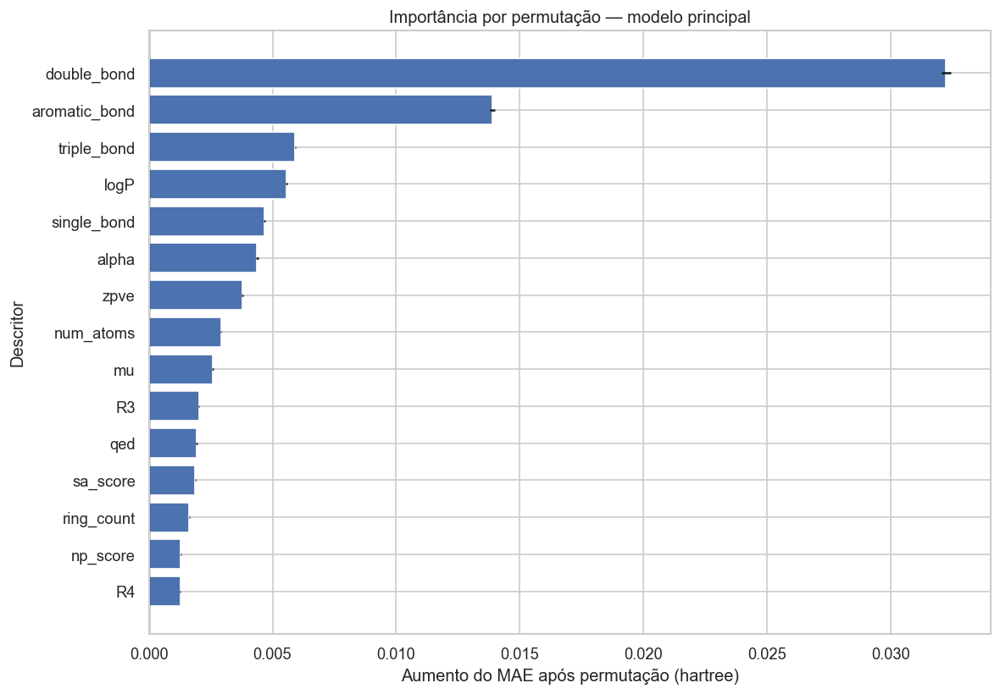

In [22]:
resultado_permutacao = permutation_importance(
    modelo_campeao,
    X_teste,
    y_teste,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=1)
 
df_importancia = pd.DataFrame({
    "Descritor": X_teste.columns,
    "Importância média": resultado_permutacao.importances_mean,
    "Desvio entre repetições": resultado_permutacao.importances_std}).sort_values("Importância média", ascending=False).reset_index(drop=True)
 
display(df_importancia.head(15))
 
top_importancia = df_importancia.head(15).sort_values("Importância média")
 
plt.figure(figsize=(10, 7))

plt.barh(
    top_importancia["Descritor"],
    top_importancia["Importância média"],
    xerr=top_importancia["Desvio entre repetições"])

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Aumento do MAE após permutação (hartree)")
plt.ylabel("Descritor")
plt.title("Importância por permutação — modelo principal")
plt.tight_layout()
plt.show()

A análise de importância por permutação no conjunto de teste revelou que os descritores moleculares de maior impacto preditivo são *double_bond* (aumento médio no MAE de $+0,0322 \text{ Ha}$ ao ser permutado) e *aromatic_bond* ($+0,0138 \text{ Ha}$), seguidos por *triple_bond*, logP e *single_bond*. As variações mínimas em variáveis irrelevantes decorrem de ruído aleatório na amostragem por permutação. Do ponto de vista químico, esses resultados confirmam que a densidade e o grau de conjugação dos elétrons $\text{π}$ (ligações duplas, triplas e aromáticas) são os fatores dominantes na determinação da energia dos orbitais de fronteira e da magnitude do gap HOMO–LUMO [1].

---

## Análise Complementar de Dimensionalidade
Como análise complementar, serão investigadas a variância explicada pela Análise de Componentes Principais (PCA) e a variabilidade dos atributos.
 
O PCA transforma os descritores originais em combinações lineares ortogonais, ordenadas pela variância explicada. Essa técnica permite caracterizar a redundância estatística presente no espaço de atributos [4].
 
A variância explicada não é equivalente à informação relevante para prever o gap: uma direção com elevada variância pode ter pouca relação com a variável-alvo. Por isso, esta análise apresenta o PCA como diagnóstico exploratório. Separadamente, a otimização também comparará pipelines com e sem PCA, sem substituir automaticamente os descritores originais.
 
A curva exploratória será ajustada apenas no conjunto de treinamento, mantendo o teste fora das decisões de transformação. Nos modelos otimizados, a imputação, a padronização e a PCA serão ajustadas dentro de cada fold por meio do Pipeline, evitando vazamento entre treinamento e validação.

Componentes para atingir pelo menos 95% da variância: 15 de 24


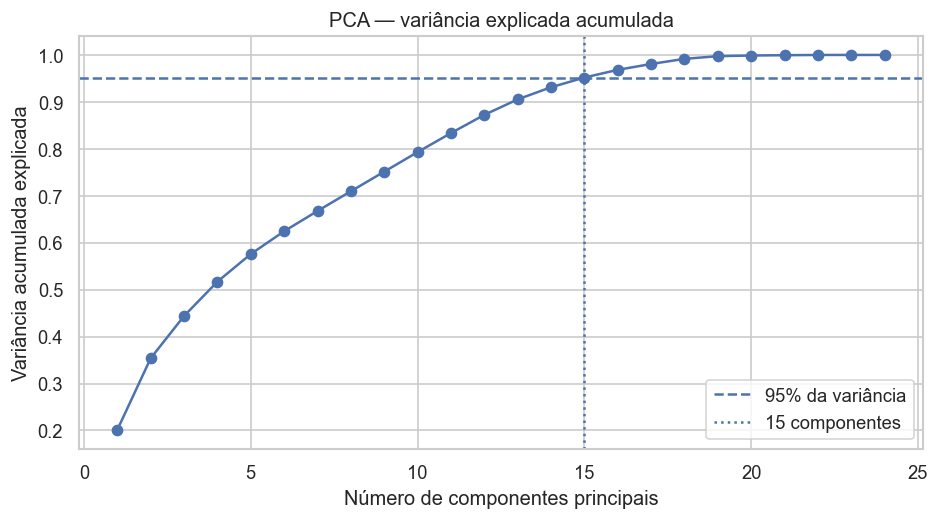

In [23]:
imputador_pca = SimpleImputer(strategy="median")
X_treino_imp = imputador_pca.fit_transform(X_treino)
 
escalador_pca = StandardScaler()
X_treino_pad = escalador_pca.fit_transform(X_treino_imp)
 
pca = PCA(random_state=SEMENTE_ALEATORIA)
pca.fit(X_treino_pad)
 
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)
n_componentes_95 = np.searchsorted(variancia_acumulada, 0.95) + 1
 
print(f"Componentes para atingir pelo menos 95% da variância: {n_componentes_95} de {X_treino.shape[1]}")
 
plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, len(variancia_acumulada) + 1), variancia_acumulada, marker="o")
plt.axhline(0.95, linestyle="--", label="95% da variância")
plt.axvline(n_componentes_95, linestyle=":", label=f"{n_componentes_95} componentes")
plt.xlabel("Número de componentes principais")
plt.ylabel("Variância acumulada explicada")
plt.title("PCA — variância explicada acumulada")
plt.legend()
plt.tight_layout()
plt.show()

A Análise de Componentes Principais (PCA) demonstrou que são necessários **15 componentes principais** para explicar 95% da variância acumulada entre os 24 descritores originais do QM9. Contudo, a variância explicada não equivale diretamente à relevância preditiva para a variável-alvo gap, pois direções de menor variância global podem conter informações decisivas para prever a energia dos orbitais quânticos. Além disso, a transformação por PCA substitui descritores físicos diretos (como contagem de ligações duplas e aromáticas) por combinações lineares abstratas, prejudicando a interpretabilidade química do modelo.
 
Cabe ressaltar ainda que, ao incluir a presença da PCA como um hiperparâmetro categórico no espaço de busca do Optuna (`usar_pca: True/False`), observou-se que todos os modelos campeões baseados em conjuntos de árvores (*Extra Trees*, *Random Forest*, *HistGradientBoosting* e *Gradient Boosting*), assim como o k-NN, selecionaram pipelines sem PCA (`usar_pca: False`). Isso pode ser justificado pois as tranformações lineares da PCA misturam descritores físicos e prejudicam as divisões ortogonais diretas feitas pelos algoritmos de árvores de variáveis discretas.

---

## Síntese dos Resultados
Nesta etapa, os resultados da análise exploratória, da comparação inicial, da otimização e da avaliação final serão integrados para responder à pergunta central do projeto: em que medida os descritores selecionados permitem estimar o gap HOMO–LUMO no conjunto QM9?

In [24]:
linha_baseline = tabela_final.loc[tabela_final["Modelo"] == "Baseline (média)"].iloc[0]
linha_campeao_teste = tabela_final.iloc[0]
 
mae_baseline = linha_baseline["MAE (hartree)"]
mae_melhor_teste = linha_campeao_teste["MAE (hartree)"]
 
reducao_mae = (100 * (mae_baseline - mae_melhor_teste) / mae_baseline if mae_baseline > 0 else np.nan)
 
print("SÍNTESE DOS RESULTADOS FINAIS")
print("=" * 55)
print(f"Modelo com menor MAE no teste: {linha_campeao_teste['Modelo']}")
print(f"MAE do baseline: {mae_baseline:.6f} Ha")
print(f"MAE do melhor modelo no teste: {mae_melhor_teste:.6f} Ha")
print(f"RMSE do melhor modelo no teste: {linha_campeao_teste['RMSE (hartree)']:.6f} Ha")
print(f"R² do melhor modelo no teste: {linha_campeao_teste['R2']:.6f}")
print(f"Redução do MAE em relação ao baseline: {reducao_mae:.2f}%")
print(f"Modelo selecionado pela validação: {nome_campeao}")
 
print("\nTOP 5 DESCRITORES POR IMPORTÂNCIA")
display(df_importancia.head(5))

SÍNTESE DOS RESULTADOS FINAIS
Modelo com menor MAE no teste: Extra Trees
MAE do baseline: 0.039492 Ha
MAE do melhor modelo no teste: 0.009011 Ha
RMSE do melhor modelo no teste: 0.012591 Ha
R² do melhor modelo no teste: 0.929381
Redução do MAE em relação ao baseline: 77.18%
Modelo selecionado pela validação: Extra Trees

TOP 5 DESCRITORES POR IMPORTÂNCIA


,Descritor,Importância média,Desvio entre repetições
0,double_bond,0.032238,0.000181
1,aromatic_bond,0.013899,0.000098
2,triple_bond,0.005924,0.000033
3,logP,0.005559,0.000032
4,single_bond,0.004668,0.000031


O aprendizado de máquina supervisionado provou ser altamente eficaz para prever o gap HOMO–LUMO no QM9, atingindo um MAE final de $0.009011\text{ Ha}$ ($≈ 0,2452 \text{ eV}$) e $R²=0.929381$, reduzindo o erro em 77,18% em relação ao modelo baseline trivial. Os métodos baseados em conjuntos de árvores não-lineares (*Extra Trees*, *Random Forest* e *HistGradientBoosting*) apresentaram desempenho nitidamente superior aos modelos lineares regularizados (Regressão Ridge, $MAE=0.507422	\text{ eV}$), confirmando que a relação entre a estrutura molecular e a energia dos orbitais é **fortemente não-linear**. Nesse contexto, a análise por permutação demonstrou que a presença de insaturações e conjugações  $\text{π}$ (*double_bond*, *aromatic_bond*, *triple_bond*) exercem o papel primário na predição do gap quântico.

---

## Conclusão
O presente estudo investigou a capacidade de algoritmos de aprendizado de máquina supervisionados para estimar o *gap* HOMO-LUMO de pequenas moléculas orgânicas a partir de descritores topológicos e físico-químicos do conjunto de dados QM9 [1].

O modelo campeão (**Extra Trees Regressor**) atingiu uma Erro Absoluto Médio (**MAE**) no conjunto de teste reservado de $0,009011 \text{ hartree}$ (equivalente a $0,2452 \text{ eV}$), com Raiz do Erro Quadrático Médio (**RMSE**) de $0,012591 \text{ hartree}$ e Coeficiente de Determinação (**R²**) de **0,929381**. Em comparação com o modelo **baseline** trivial da média ($MAE=0,039492 \text{ Ha} ≈ 1,0746 \text{ eV}), o modelo principal promoveu uma **redução de 77,18% no erro absoluto de previsão**.

Os algoritmos baseados em **conjuntos de árvores** de decisão **não-lineares** (*Extra Trees*, *Random Forest* e *HistGradientBoosting*) apresentaram desempenho nitidamente superior aos modelos lineares regularizados (Regressão *Ridge*, $MAE=0,5074 \text{ eV}$). O ranking de desempenho observado na validação cruzada durante o treinamento foi confirmado no conjunto de teste independente. A proximidade entre o MAE e o RMSE nos modelos de árvores confirma a baixa incidência de erros discrepantes extremos.

A análise de importância por permutação revelou que os descritores moleculares com maior impacto preditivo são a contagem de ligações duplas (*double_bond*), ligações aromáticas (*aromatic_bond*), ligações triplas (*triple_bond*) e o parâmetro de lipofilicidade (logP). Do ponto de vista físico-químico, a presença de insaturações e elétrons $\pi$ deslocalizados governa diretamente o grau de conjugação molecular e as energias dos orbitais de fronteira (HOMO e LUMO).

Cabe ressaltar que a exclusão preventiva das variáveis `homo`e `lumo` (evitando a relação matemática direta $\text{gap} = \text{LUMO} - \text{HOMO}$) e das propriedades termoquímicas garantiu que o modelo aprendesse padrões estruturais genuínos, e que a aplicação de transformadores (`StandardScaler`) estritamente dentro dos folds de validação cruzada evitou a contaminação de informações de teste no treinamento. Além disso, a Análise de Componentes Principais (PCA) indicou que 15 componentes explicam 95% da variância, contudo, a otimização no Optuna demonstrou que manter os descritores físicos originais sem PCA gerou melhores resultados nos modelos de árvores.

Portanto, os resultados refletem a capacidade de estimar propriedades calculadas por química quântica dentro do domínio amostral específico do QM9 (moléculas com até nove átomos pesados) [1], mas é válido reiterar que o modelo não prevê diretamente o gap óptico experimental e, dessa forma, requer validação adicional antes de ser aplicado a estruturas moleculares externas de maior complexidade.

---

## Referências
1. RAMAKRISHNAN, Raghunathan; DRAL, Pavlo O.; RUPP, Matthias; VON LILIENFELD, O. Anatole. Quantum chemistry structures and properties of 134 kilo molecules. **Scientific Data**, v. 1, p. 140022, 2014. DOI: 10.1038/sdata.2014.22.
2. RAMAKRISHNAN, Raghunathan; DRAL, Pavlo O.; RUPP, Matthias; VON LILIENFELD, O. Anatole. **Quantum chemistry structures and properties of 134 kilo molecules** (QM9) [Dataset]. Figshare, 2014. DOI: 10.6084/m9.figshare.978904.v1.
3. SCHIFF, Yair. **QM9 Dataset**: Quantum chemistry structures and properties of 134k organic molecules. Hugging Face Datasets, 2020. Disponível em: https://huggingface.co/datasets/yairschiff/qm9.
4. CASSAR, Daniel R. **Aulas e Materiais Didáticos de Aprendizado de Máquina** (Notebooks 1 a 14). Campinas: Ilum Escola de Ciência, 2026.
5. AKIBA, Takuya; SANO, Shotaro; YANASE, Toshihiko; OHTA, Takeru; KOYAMA, Masanori. Optuna: A next-generation hyperparameter optimization framework. In: ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY & DATA MINING, 25., 2019, Anchorage. **Proceedings...** Anchorage: ACM, 2019. p. 2623-2631.
6. GEURTS, Pierre; ERNST, Damien; WEHENKEL, Louis. Extremely randomized trees. **Machine Learning**, v. 63, n. 1, p. 3-42, 2006.
7. KE, Guolin et al. LightGBM: A highly efficient gradient boosting decision tree. **Advances in Neural Information Processing Systems**, v. 30, p. 3146-3154, 2017.
8. FRIEDMAN, Jerome H. Greedy function approximation: a gradient boosting machine. **Annals of Statistics**, v. 29, n. 5, p. 1189-1232, 2001.
9. HOERL, Arthur E.; KENNARD, Robert W. Ridge regression: Biased estimation for nonorthogonal problems. **Technometrics**, v. 12, n. 1, p. 55-67, 1970.
10. STROBL, Carolin; BOULESTEIX, Anne-Laure; KNEIB, Thomas; AUGUSTIN, Thomas; ZEILEIS, Achim. Conditional variable importance for random forests. **BMC Bioinformatics**, v. 9, p. 307, 2008.

### Uso de IA
Foi utilizada Inteligência Artificial para auxiliar a busca por um conjunto de dados de interesse, para debater quais algoritmos, entre as opções que eu tinha, seriam mais interessantes nessa aplicação, para auxiliar a formatar os gráficos (principalmente na hora de definir as dimensões, porque eles estavam ficando bem feinhos rsr), para definir a licença no GitHub e para ajudar a alterar algumas coisas na carta de apresentação ao Rei Milu Iluminarius.